<a href="https://colab.research.google.com/github/Sands225/Gallstone-Classification/blob/main/%5BMachine_Learning%5D_Gallstone_Disease_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Kelompok 5: Gallstone Classification

**Mata Kuliah** : \
Machine Learning A

\
**Dosen Pengampu** :  \
Dr. Ir. I Wayan Agus Surya Darma, S.Kom., M.T.

\
**Anggota Kelompok**:
| NIM | Nama |
| --- | --- |
| 2405551007 | I Gusti Bagus Narendratanaya Wiweka |
| 2405551025 | I Gde Made Fajar Harry Putra Utama |
| 2405551026 | I Putu Raditya Dharma Yoga |
| 2405551056 | Anak Agung Ngurah Figo Laksmana Saputra |
| 2405551082 | I Made Sandika Wijaya |

In [ ]:
!pip -q install xgboost lightgbm shap lime "scikit-learn>=1.5"

In [ ]:
import pandas as pd
import numpy as np
from google.colab import drive
import os
import math
import shap

import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer

from sklearn.model_selection import train_test_split

from sklearn.base import clone
from sklearn.model_selection import (
  StratifiedKFold, RepeatedStratifiedKFold,
  cross_validate, TunedThresholdClassifierCV
)
from sklearn.ensemble import (
  RandomForestClassifier,
  ExtraTreesClassifier,
  GradientBoostingClassifier,
  VotingClassifier,
  StackingClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
  accuracy_score,
  precision_score,
  recall_score,
  f1_score,
  make_scorer,
  brier_score_loss,
  classification_report,
  confusion_matrix,
  ConfusionMatrixDisplay
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import zipfile
from IPython.display import display
from lime.lime_tabular import LimeTabularExplainer


In [ ]:
# ============ KONFIGURASI GLOBAL & HELPER UNTUK LAPORAN ============
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE   = 42
POSITIVE_CLASS = 1                           # kelas positif untuk Precision, Recall, F1, Brier, DCA
CLASS_LABELS   = ['0 (Sakit)', '1 (Sehat)']  # sesuai Tabel 3.1

FIG_DIR, TABLE_DIR = 'figures', 'tables'
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

VARIANT_COLORS = {'Top-3': '#2E75B6', '7 Model': '#ED7D31'}
ENS_ORDER      = ['Hard Voting', 'Soft Voting', 'Stacking']

# Gaya seragam semua gambar (siap tempel ke Word: latar putih, font jelas, 300 dpi)
plt.rcParams.update({
  'figure.dpi': 110, 'savefig.dpi': 300, 'figure.facecolor': 'white',
  'font.size': 11, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
  'axes.labelsize': 11, 'axes.spines.top': False, 'axes.spines.right': False,
  'axes.grid': False, 'legend.frameon': False
})

TABLES = {}

def save_fig(name, show=True):
  """Simpan gambar aktif ke figures/<name>.png (300 dpi) lalu tampilkan."""
  path = os.path.join(FIG_DIR, f'{name}.png')
  plt.savefig(path, dpi=300, bbox_inches='tight', facecolor='white')
  print(f'[Gambar tersimpan] {path}')
  plt.show() if show else plt.close()

def save_table(table, name, decimals=4, show=True):
  """Simpan tabel ke tables/<name>.csv dan masukkan ke workbook Excel akhir."""
  out = table.round(decimals) if hasattr(table, 'round') else table
  TABLES[name[:31]] = out
  out.to_csv(os.path.join(TABLE_DIR, f'{name}.csv'), encoding='utf-8-sig')
  if show:
    display(out)
  return out

print('Konfigurasi siap. Gambar -> ./figures, tabel -> ./tables')

Konfigurasi siap. Gambar -> ./figures, tabel -> ./tables


## Data Collection

In [ ]:
try:
  df = pd.read_csv('/content/dataset-uci.csv', sep=None, engine='python', decimal=',')
  print("Dataset berhasil dibaca dari local Colab.")

except Exception as e:
  try:
    if not os.path.exists('/content/drive/MyDrive'):
      drive.mount('/content/drive')

    df = pd.read_csv('/content/drive/MyDrive/College/Machine Learning/gallstone_dataset/dataset-uci.csv')
    print("Dataset berhasil dibaca dari Google Drive.")

  except Exception as e:
        print(f"Gagal membaca dari Google Drive: {e}")

df.head()

Dataset berhasil dibaca dari local Colab.


,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,0,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6


## Exploratory Data Analysis (EDA)


Exploratory Data Analysis atau EDA dilakukan dengan tahapan sebagai berikut.
1. Membagi dataset ke dalam `categorical` features dan `numerical` features
2. Melihat informasi numerical dan categorical features
3. Analisis Distribusi dan Skewness
4. Analisis Outlier
5. Analisis Korelasi Fitur dengan `Pearson Correlation`
6. Analisis Variable Influence Factor (VIF)
7. Analisis Asosiasi menggunakan `Cramér’s V`

In [ ]:
# Membagi DataFrame berdasarkan tipe data
cat_cols = [
  'Gender',
  'Comorbidity',
  'Coronary Artery Disease (CAD)',
  'Hypothyroidism',
  'Hyperlipidemia',
  'Diabetes Mellitus (DM)',
  'Hepatic Fat Accumulation (HFA)',
  'Gallstone Status'
]

num_cols = [col for col in df.columns if col not in cat_cols]

print(f"Jumlah Categorical Features: {len(cat_cols)}")
print(f"Jumlah Numerical Features: {len(num_cols)}\n")

print("Categorical Features:")
for col in cat_cols:
  print(col)

print("\nNumerical Features:")
for col in num_cols:
  print(col)

Jumlah Categorical Features: 8
Jumlah Numerical Features: 31

Categorical Features:
Gender
Comorbidity
Coronary Artery Disease (CAD)
Hypothyroidism
Hyperlipidemia
Diabetes Mellitus (DM)
Hepatic Fat Accumulation (HFA)
Gallstone Status

Numerical Features:
Age
Height
Weight
Body Mass Index (BMI)
Total Body Water (TBW)
Extracellular Water (ECW)
Intracellular Water (ICW)
Extracellular Fluid/Total Body Water (ECF/TBW)
Total Body Fat Ratio (TBFR) (%)
Lean Mass (LM) (%)
Body Protein Content (Protein) (%)
Visceral Fat Rating (VFR)
Bone Mass (BM)
Muscle Mass (MM)
Obesity (%)
Total Fat Content (TFC)
Visceral Fat Area (VFA)
Visceral Muscle Area (VMA) (Kg)
Glucose
Total Cholesterol (TC)
Low Density Lipoprotein (LDL)
High Density Lipoprotein (HDL)
Triglyceride
Aspartat Aminotransferaz (AST)
Alanin Aminotransferaz (ALT)
Alkaline Phosphatase (ALP)
Creatinine
Glomerular Filtration Rate (GFR)
C-Reactive Protein (CRP)
Hemoglobin (HGB)
Vitamin D


In [ ]:
# Informasi Numerical Features
print("=== NUMERICAL FEATURES ===")
print(f"Jumlah fitur: {len(num_cols)}")

save_table(df[num_cols].describe().T, 'eda_statistik_numerik')

# Informasi Categorical Features
print("\n=== CATEGORICAL FEATURES ===")
print(f"Jumlah fitur: {len(cat_cols)}")

cat_info = pd.DataFrame({
  'Data Type': df[cat_cols].dtypes.astype(str),
  'Missing Values': df[cat_cols].isnull().sum(),
  'Unique Values': df[cat_cols].nunique(),
  'Categories': [
    df[col].dropna().unique().tolist()
    for col in cat_cols
  ]
})

save_table(cat_info, 'eda_info_kategorikal')

=== NUMERICAL FEATURES ===
Jumlah fitur: 31


,count,mean,std,min,25%,50%,75%,max
Age,319.0,48.0690,12.1146,20.00,38.500,49.0000,56.000,96.00
Height,319.0,167.1567,10.0530,145.00,159.500,168.0000,175.000,191.00
Weight,319.0,80.5649,15.7091,42.90,69.600,78.8000,91.250,143.50
Body Mass Index (BMI),319.0,28.8771,5.3137,17.40,25.250,28.3000,31.850,49.70
Total Body Water (TBW),319.0,40.5878,7.9302,13.00,34.200,39.8000,47.000,66.20
Extracellular Water (ECW),319.0,17.0712,3.1619,9.00,14.800,17.1000,19.400,27.80
Intracellular Water (ICW),319.0,23.6345,5.3493,13.80,19.300,23.0000,27.550,57.10
Extracellular Fluid/Total Body Water (ECF/TBW),319.0,42.2120,3.2445,29.23,40.075,42.0000,44.000,52.00
Total Body Fat Ratio (TBFR) (%),319.0,28.2750,8.4444,6.30,22.025,27.8200,34.810,50.92
Lean Mass (LM) (%),319.0,71.6382,8.4376,48.99,65.165,72.1100,77.850,93.67



=== CATEGORICAL FEATURES ===
Jumlah fitur: 8


,Data Type,Missing Values,Unique Values,Categories
Gender,int64,0,2,"[0, 1]"
Comorbidity,int64,0,4,"[0, 1, 3, 2]"
Coronary Artery Disease (CAD),int64,0,2,"[0, 1]"
Hypothyroidism,int64,0,2,"[0, 1]"
Hyperlipidemia,int64,0,2,"[0, 1]"
Diabetes Mellitus (DM),int64,0,2,"[0, 1]"
Hepatic Fat Accumulation (HFA),int64,0,5,"[0, 1, 2, 3, 4]"
Gallstone Status,int64,0,2,"[0, 1]"


,Data Type,Missing Values,Unique Values,Categories
Gender,int64,0,2,"[0, 1]"
Comorbidity,int64,0,4,"[0, 1, 3, 2]"
Coronary Artery Disease (CAD),int64,0,2,"[0, 1]"
Hypothyroidism,int64,0,2,"[0, 1]"
Hyperlipidemia,int64,0,2,"[0, 1]"
Diabetes Mellitus (DM),int64,0,2,"[0, 1]"
Hepatic Fat Accumulation (HFA),int64,0,5,"[0, 1, 2, 3, 4]"
Gallstone Status,int64,0,2,"[0, 1]"


In [ ]:
# Analisis Distribusi dan Skewness
skew_df = pd.DataFrame({
  'Feature': num_cols,
  'Skewness': df[num_cols].skew().values
})

skew_df['Distribution'] = skew_df['Skewness'].apply(
  lambda x: 'Right-skewed' if x > 0.5
  else ('Left-skewed' if x < -0.5 else 'Approximately symmetric')
)

save_table(
  skew_df.sort_values('Skewness', key=abs, ascending=False).set_index('Feature'),
  'eda_skewness'
)

,Skewness,Distribution
Feature,,
Obesity (%),16.8732,Right-skewed
Alanin Aminotransferaz (ALT),7.2769,Right-skewed
Aspartat Aminotransferaz (AST),6.9945,Right-skewed
High Density Lipoprotein (HDL),6.5289,Right-skewed
Glucose,5.9378,Right-skewed
C-Reactive Protein (CRP),5.4111,Right-skewed
Triglyceride,2.7864,Right-skewed
Glomerular Filtration Rate (GFR),-1.8130,Left-skewed
Visceral Fat Area (VFA),1.0575,Right-skewed


,Skewness,Distribution
Feature,,
Obesity (%),16.8732,Right-skewed
Alanin Aminotransferaz (ALT),7.2769,Right-skewed
Aspartat Aminotransferaz (AST),6.9945,Right-skewed
High Density Lipoprotein (HDL),6.5289,Right-skewed
Glucose,5.9378,Right-skewed
C-Reactive Protein (CRP),5.4111,Right-skewed
Triglyceride,2.7864,Right-skewed
Glomerular Filtration Rate (GFR),-1.8130,Left-skewed
Visceral Fat Area (VFA),1.0575,Right-skewed


[Gambar tersimpan] figures/eda_01_distribusi_fitur_numerik.png


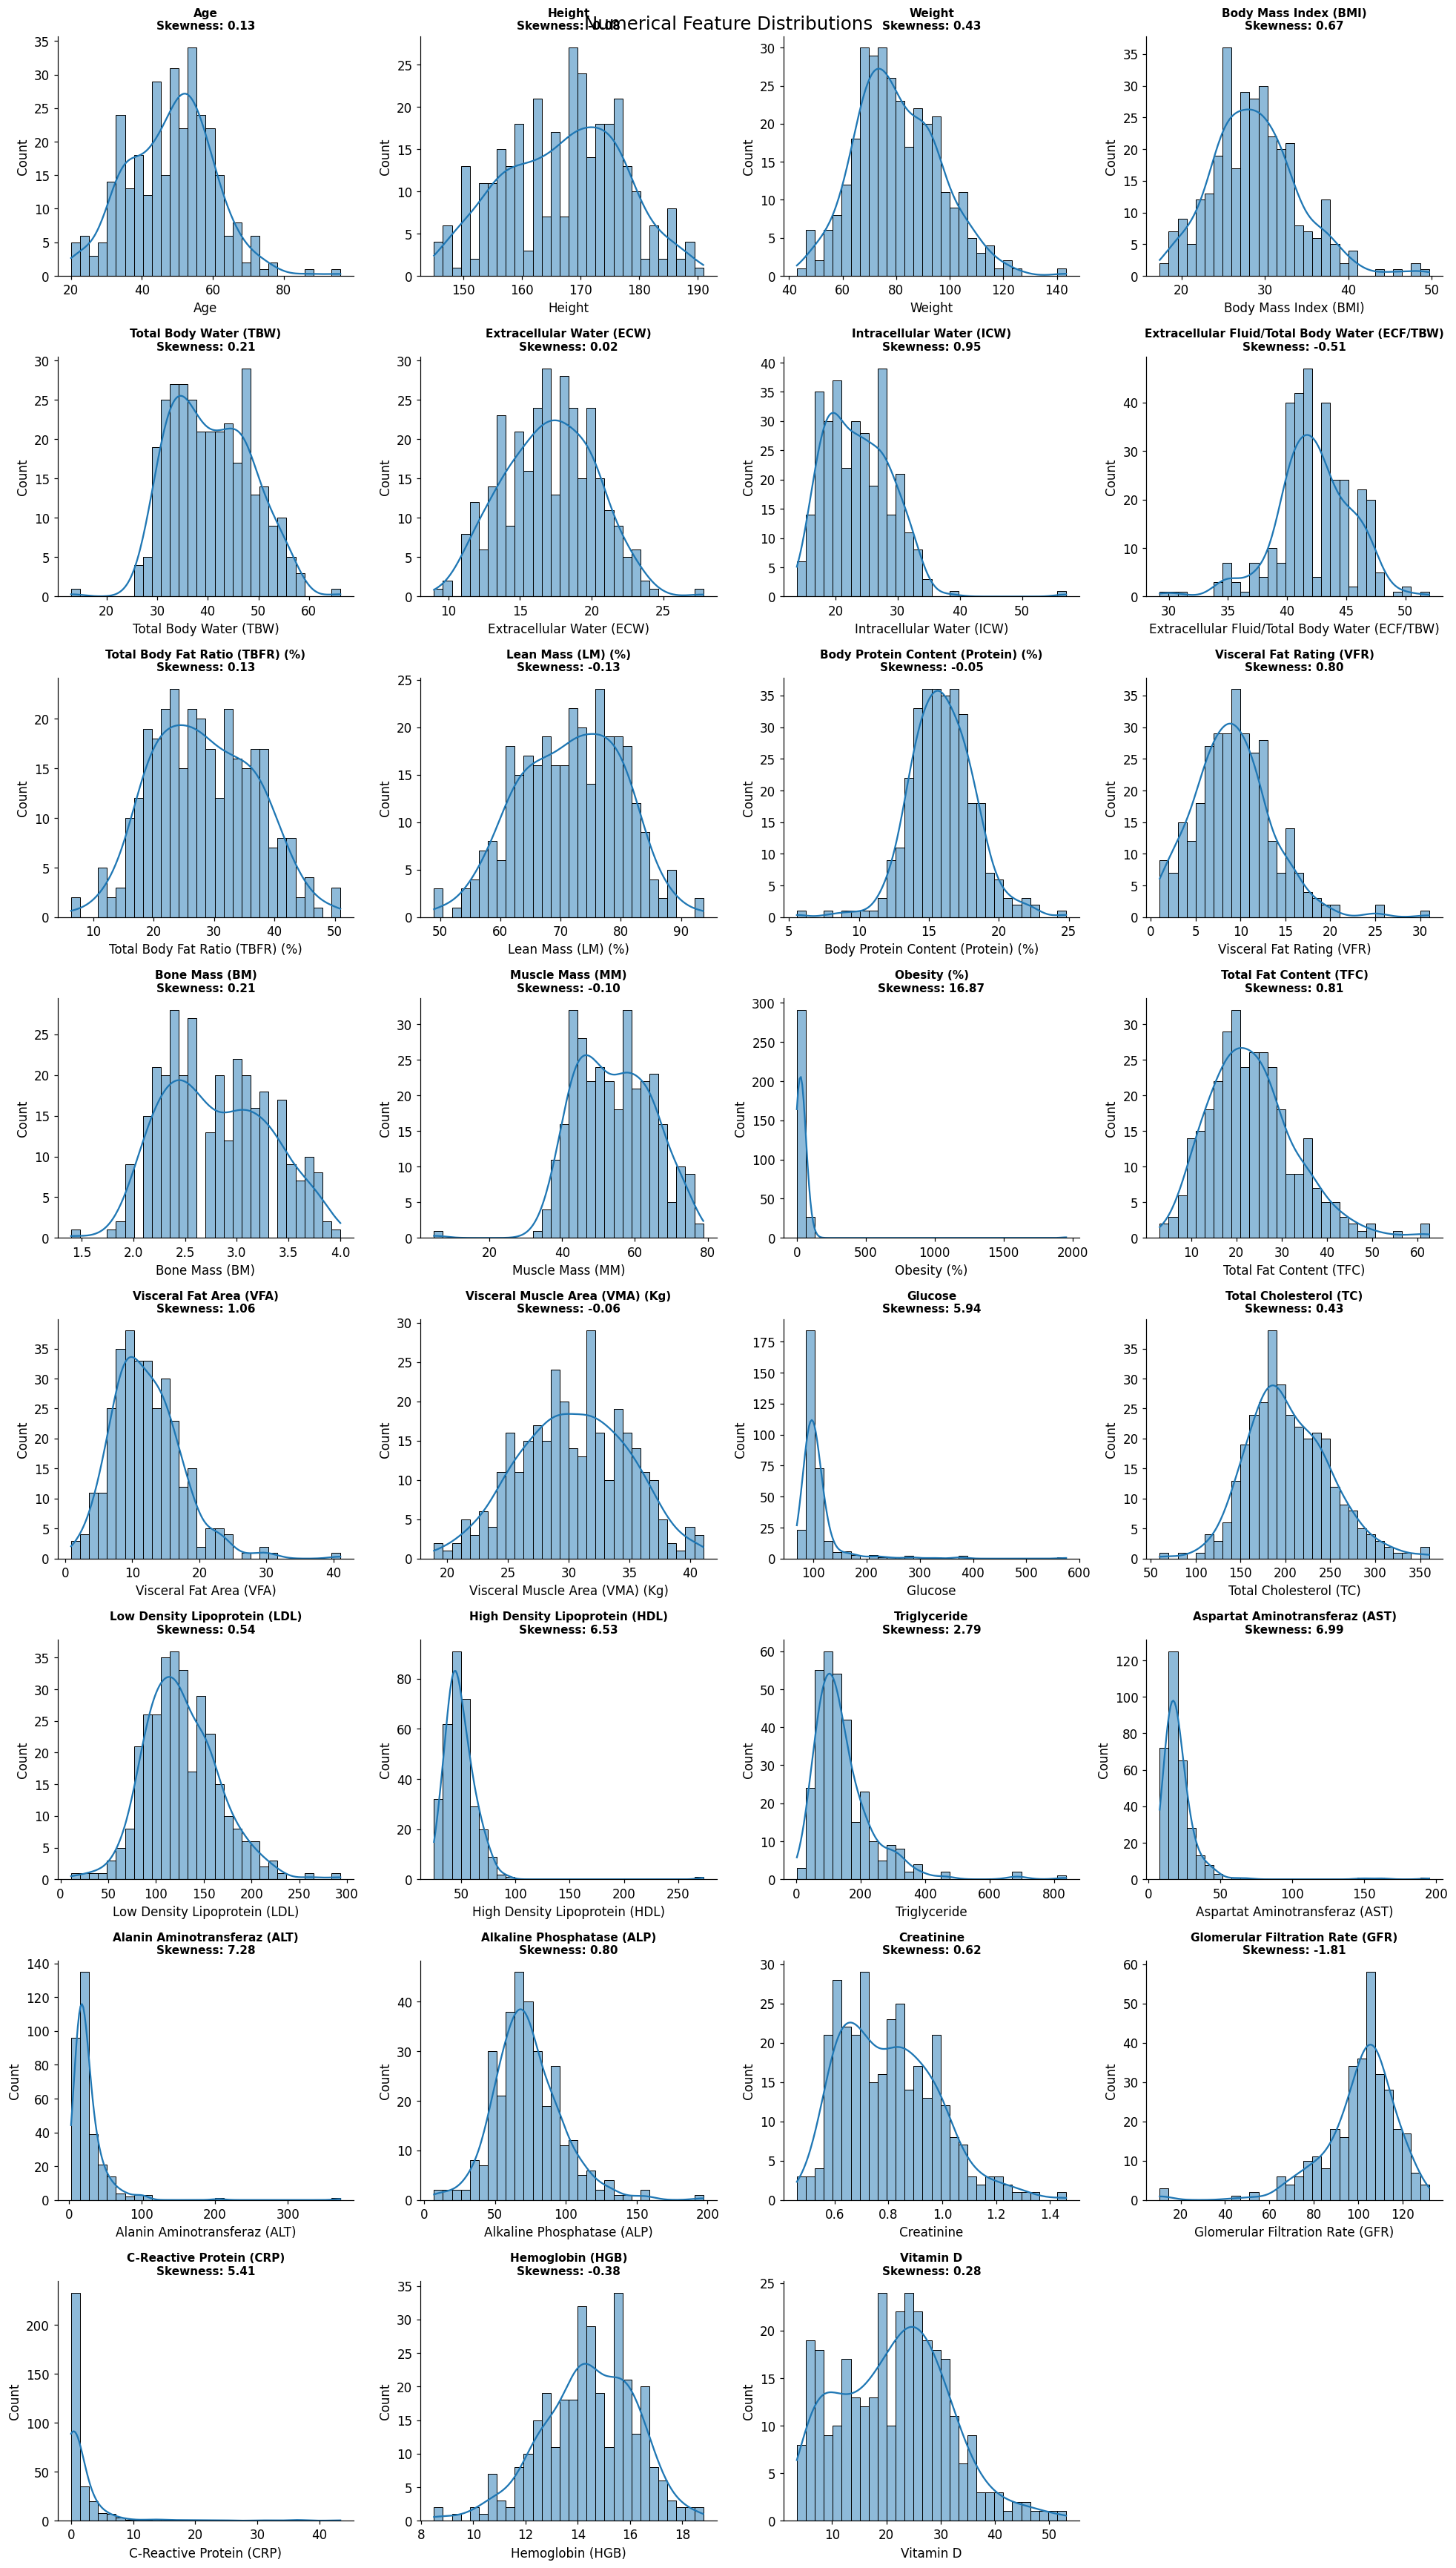

In [ ]:
# Visualisasi Distribusi Fitur Numerik
cols_per_row = 4
n_rows = math.ceil(len(num_cols) / cols_per_row)

fig, axes = plt.subplots(
  n_rows, cols_per_row,
  figsize=(18, n_rows * 4)
)

axes = axes.flatten()

for i, col in enumerate(num_cols):
  sns.histplot(df[col].dropna(), kde=True, bins=30, ax=axes[i])
  axes[i].set_title(f'{col}\nSkewness: {df[col].skew():.2f}', fontsize=10)

for i in range(len(num_cols), len(axes)):
  axes[i].set_visible(False)

plt.suptitle('Numerical Feature Distributions', fontsize=16)
plt.tight_layout()
save_fig('eda_01_distribusi_fitur_numerik')

In [ ]:
# Analisis Outlier
outlier_results = []

for col in num_cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1

  lower = Q1 - 1.5 * IQR
  upper = Q3 + 1.5 * IQR

  outliers = df[col].notna() & (
    (df[col] < lower) | (df[col] > upper)
  )

  outlier_results.append({
    'Feature': col,
    'Lower Bound': lower,
    'Upper Bound': upper,
    'Outlier Count': outliers.sum(),
    'Outlier (%)': outliers.sum() / df[col].notna().sum() * 100
    if df[col].notna().sum() > 0 else np.nan
  })

outlier_df = pd.DataFrame(outlier_results)

outlier_df = outlier_df.sort_values(
  'Outlier Count',
  ascending=False
).reset_index(drop=True)

save_table(outlier_df.set_index('Feature'), 'eda_outlier_iqr', decimals=2)

,Lower Bound,Upper Bound,Outlier Count,Outlier (%)
Feature,,,,
C-Reactive Protein (CRP),-2.42,4.04,34,10.66
Alanin Aminotransferaz (ALT),-9.38,53.62,27,8.46
Glucose,66.50,134.50,25,7.84
Aspartat Aminotransferaz (AST),3.00,35.00,23,7.21
Triglyceride,-50.50,305.50,20,6.27
Glomerular Filtration Rate (GFR),69.31,135.61,13,4.08
Alkaline Phosphatase (ALP),16.00,128.00,12,3.76
Body Protein Content (Protein) (%),10.02,21.88,8,2.51
Total Fat Content (TFC),-0.33,45.88,7,2.19


,Lower Bound,Upper Bound,Outlier Count,Outlier (%)
Feature,,,,
C-Reactive Protein (CRP),-2.42,4.04,34,10.66
Alanin Aminotransferaz (ALT),-9.38,53.62,27,8.46
Glucose,66.50,134.50,25,7.84
Aspartat Aminotransferaz (AST),3.00,35.00,23,7.21
Triglyceride,-50.50,305.50,20,6.27
Glomerular Filtration Rate (GFR),69.31,135.61,13,4.08
Alkaline Phosphatase (ALP),16.00,128.00,12,3.76
Body Protein Content (Protein) (%),10.02,21.88,8,2.51
Total Fat Content (TFC),-0.33,45.88,7,2.19


[Gambar tersimpan] figures/eda_02_boxplot_outlier.png


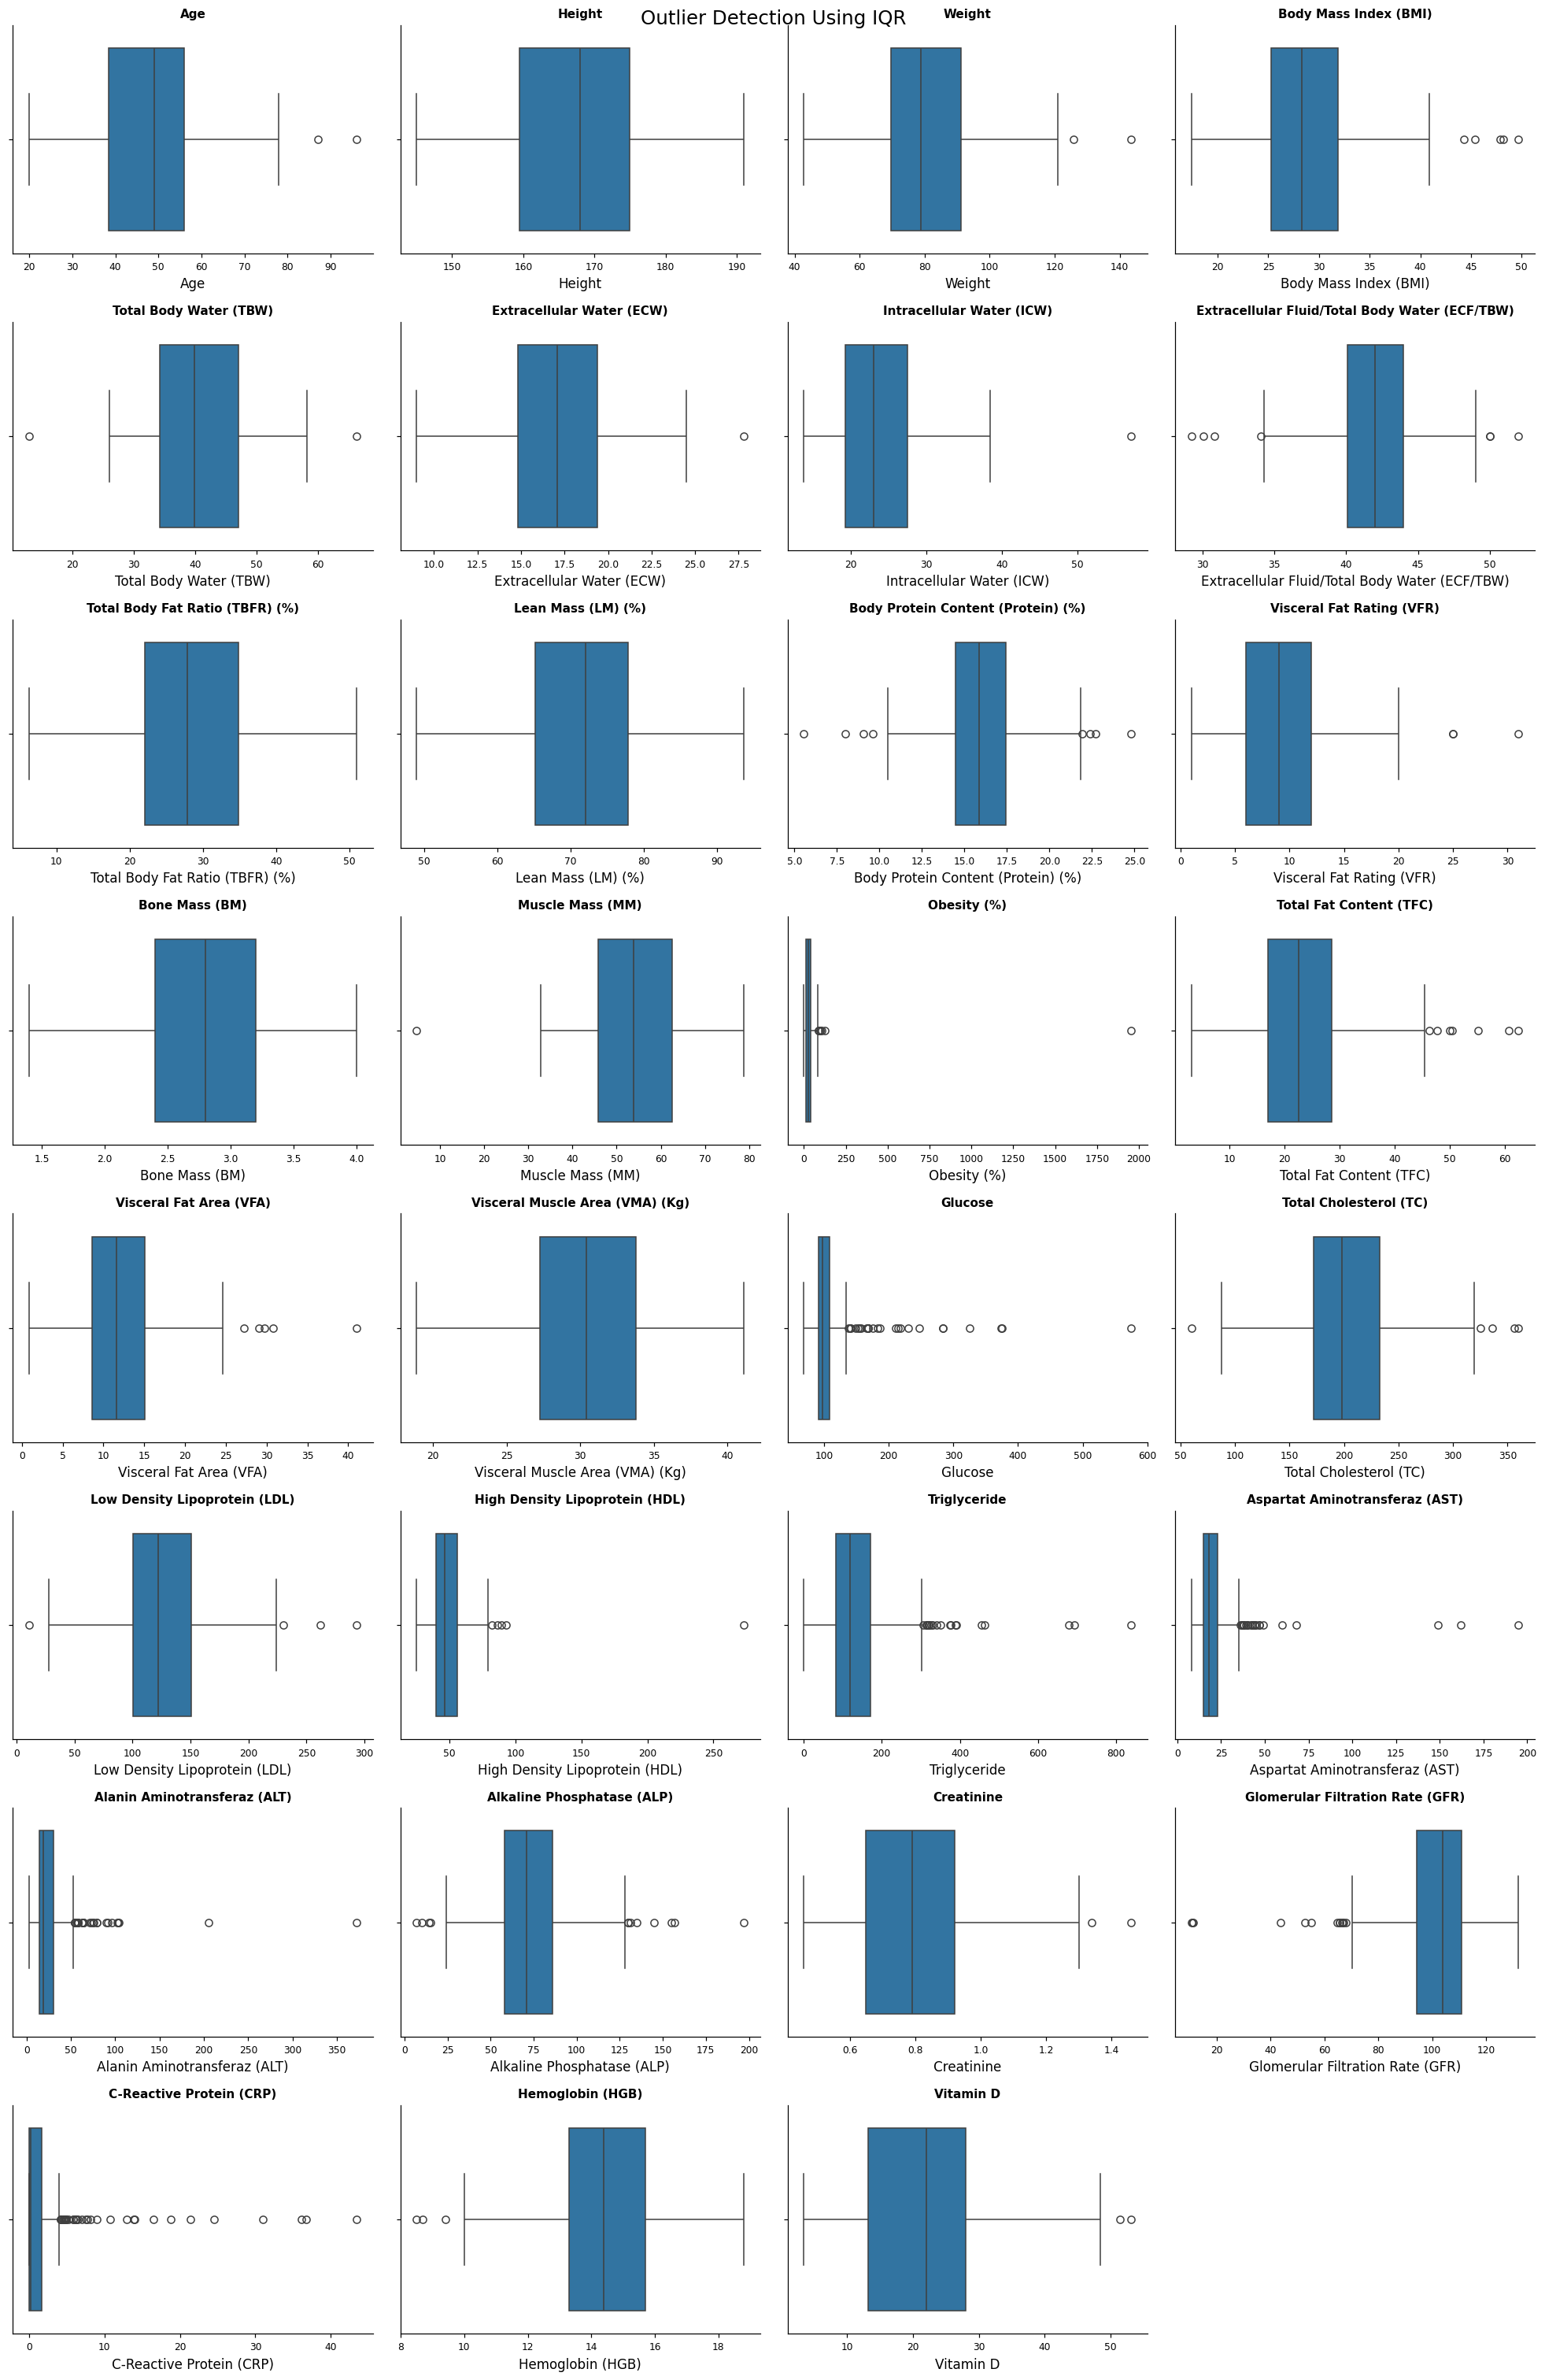

In [ ]:
# Visualisasi Outlier
cols_per_row = 4
n_rows = math.ceil(len(num_cols) / cols_per_row)

fig, axes = plt.subplots(
    n_rows,
    cols_per_row,
    figsize=(18, n_rows * 3.5)
)

axes = np.array(axes).flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(col, fontsize=10)
    axes[i].tick_params(axis='x', labelsize=8)

for i in range(len(num_cols), len(axes)):
    axes[i].set_visible(False)

plt.suptitle('Outlier Detection Using IQR', fontsize=16)
plt.tight_layout()
save_fig('eda_02_boxplot_outlier')

[Gambar tersimpan] figures/eda_03_heatmap_korelasi.png


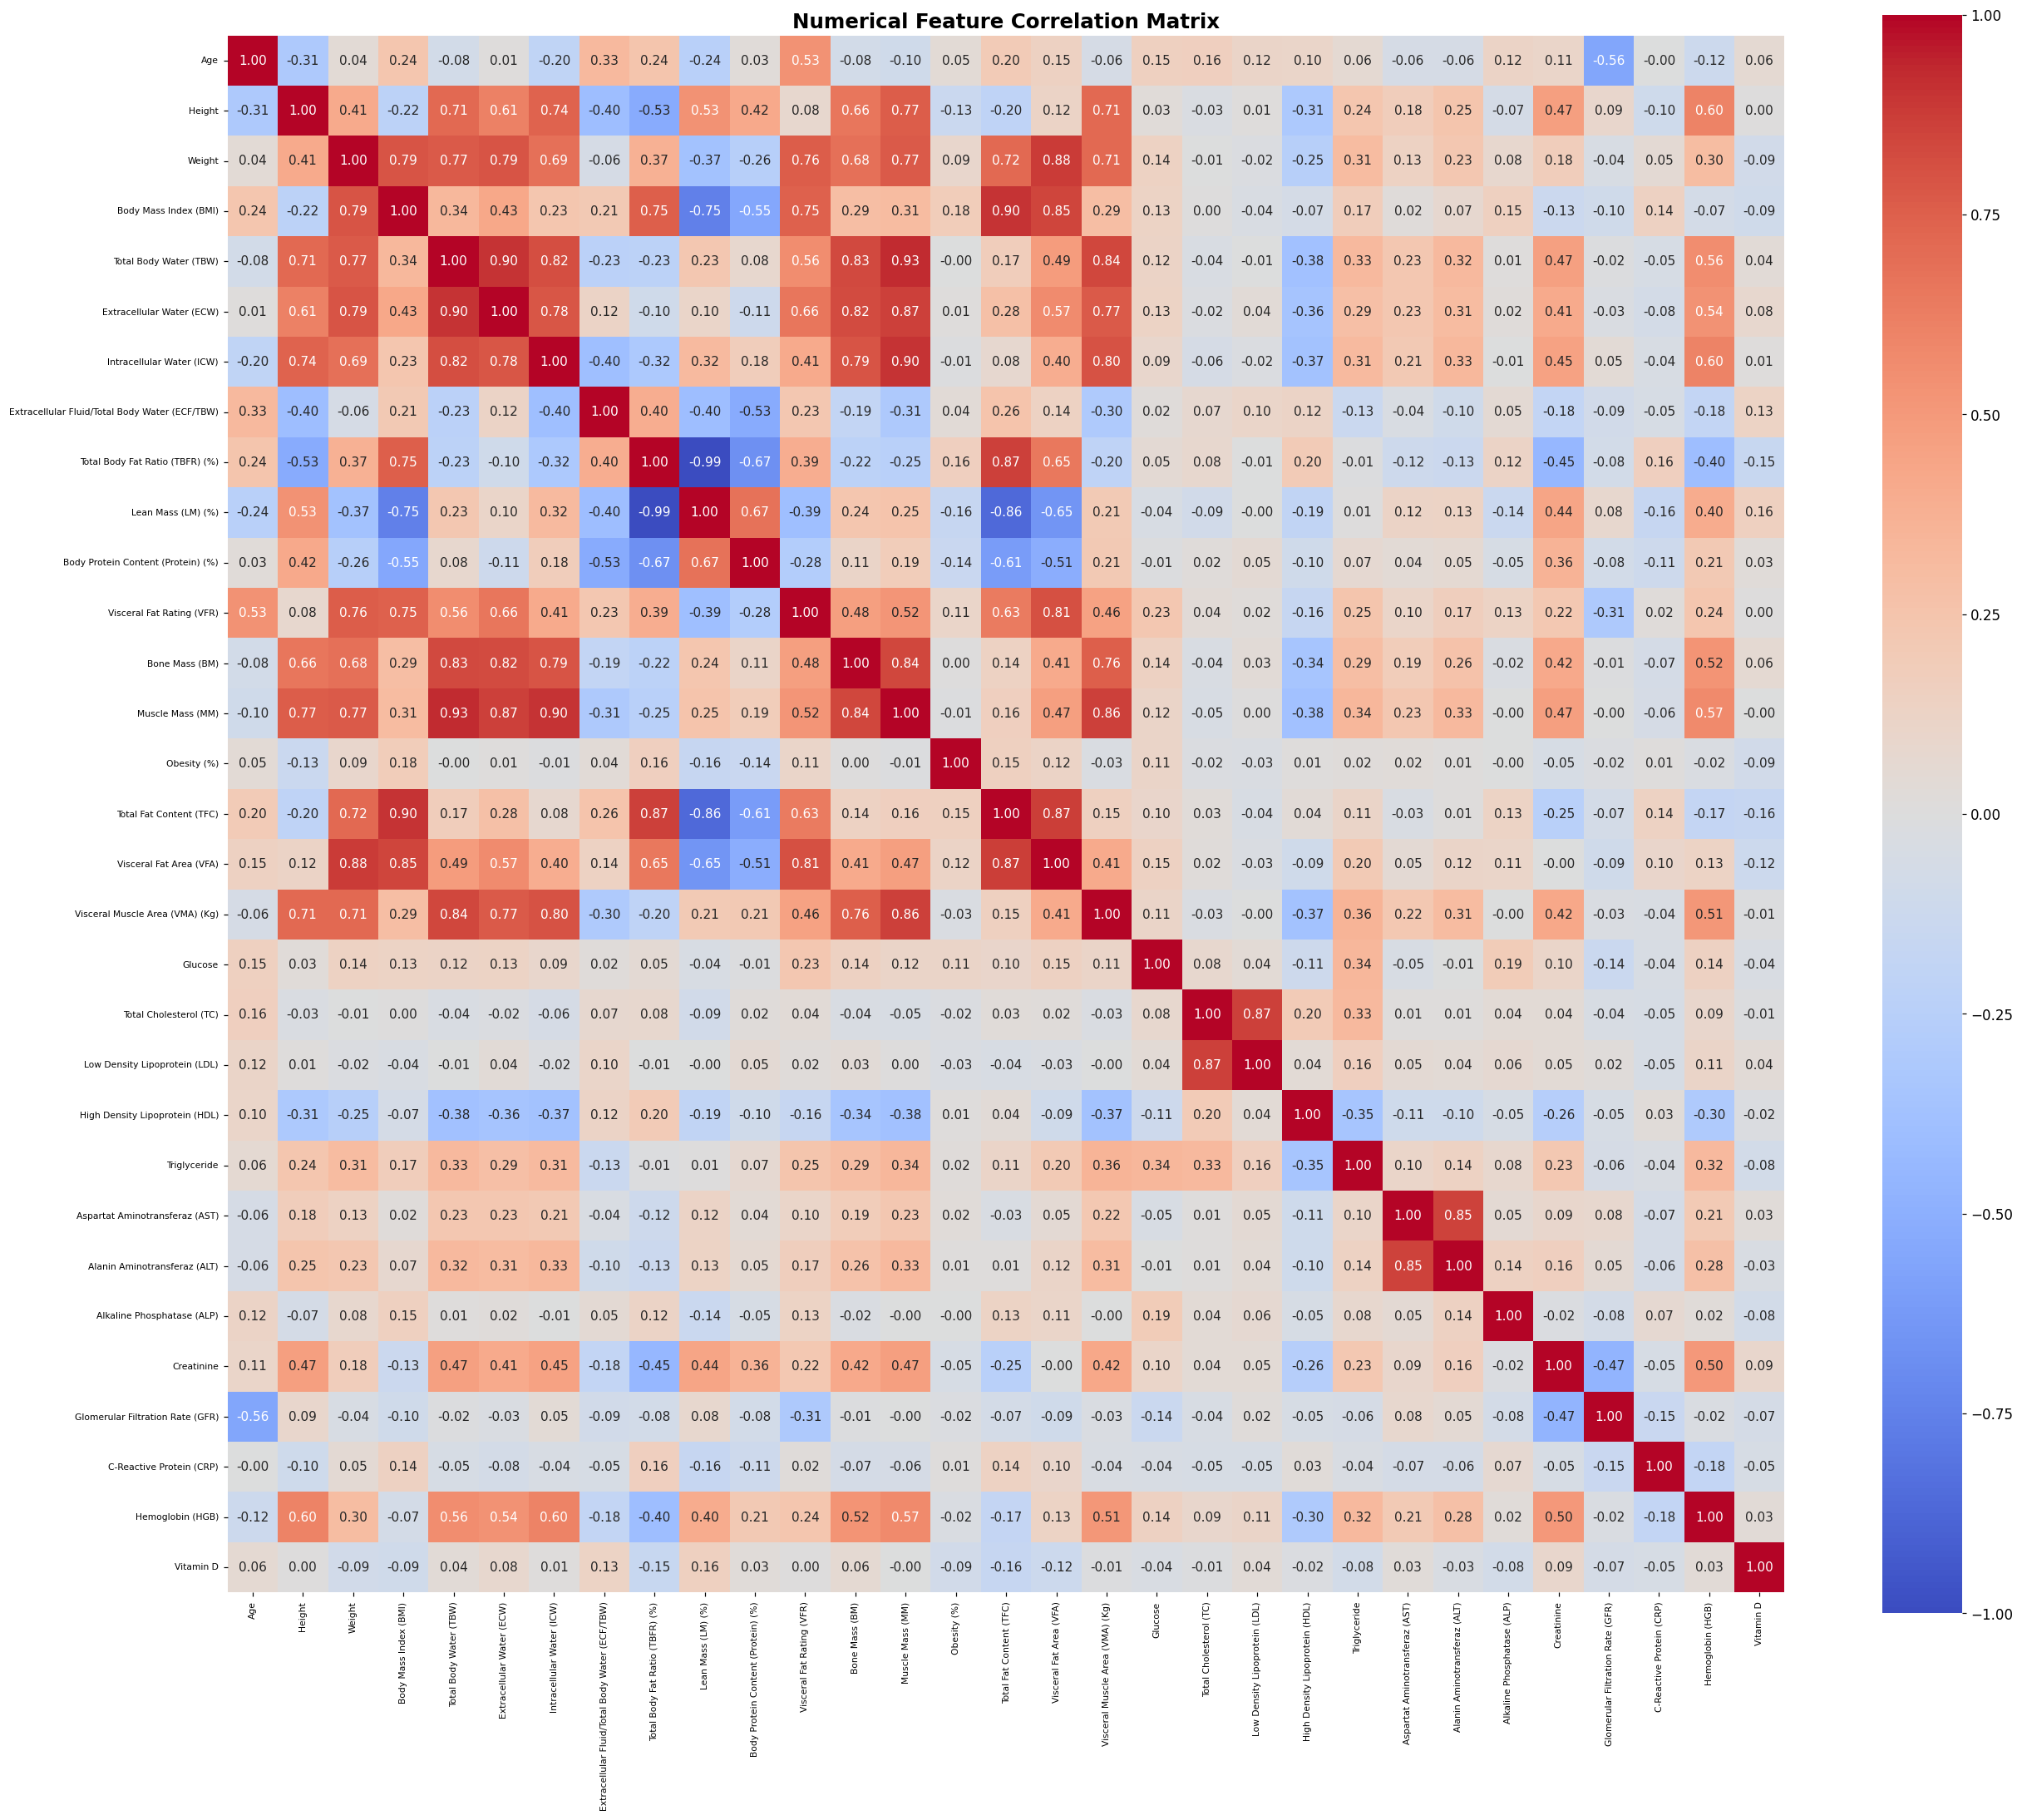

Pasangan fitur dengan korelasi absolut > 0.95:
Total Body Fat Ratio (TBFR) (%) <=> Lean Mass (LM) (%): 0.9941 (99.41%)


In [ ]:
# Analisis Korelasi Fitur
corr = df[num_cols].corr()

# Heatmap
plt.figure(figsize=(24, 20))

sns.heatmap(
  corr,
  annot=True,
  fmt='.2f',
  cmap='coolwarm',
  vmin=-1,
  vmax=1,
  center=0,
  square=True,
  annot_kws={'size': 10}
)

plt.title('Numerical Feature Correlation Matrix', fontsize=16)
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
save_fig('eda_03_heatmap_korelasi')

# Mencari pasangan fitur dengan korelasi > 0.95
upper = corr.abs().where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

print("Pasangan fitur dengan korelasi absolut > 0.95:")
found = False
for col in upper.columns:
  for row in upper.index:
    value = upper.loc[row, col]

    if pd.notna(value) and value > 0.95:
      print(f"{row} <=> {col}: {value:.4f} ({value*100:.2f}%)")
      found = True

if not found:
  print("Tidak ada pasangan fitur dengan korelasi > 0.95.")

[Gambar tersimpan] figures/eda_04_vif.png


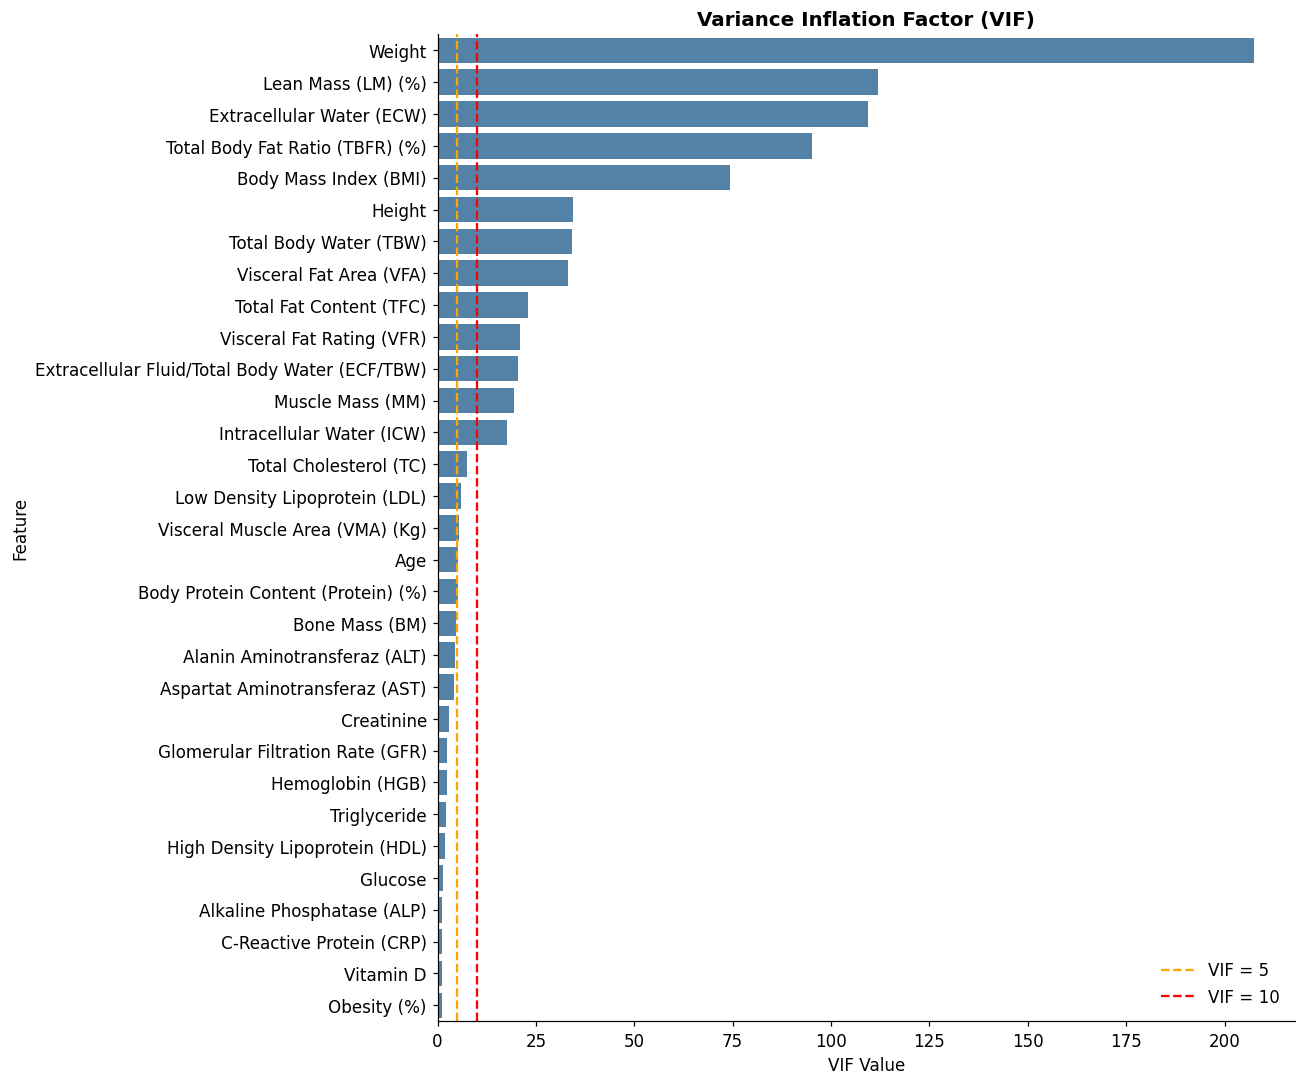

,VIF
Feature,
Weight,207.4487
Lean Mass (LM) (%),112.0473
Extracellular Water (ECW),109.4661
Total Body Fat Ratio (TBFR) (%),95.1536
Body Mass Index (BMI),74.1921
Height,34.3350
Total Body Water (TBW),34.1539
Visceral Fat Area (VFA),33.1612
Total Fat Content (TFC),22.8942


In [ ]:
# Persiapan data
X_vif = df[num_cols].dropna().copy()
X_vif = X_vif.loc[:, X_vif.nunique() > 1]

# Hitung VIF
X_const = add_constant(X_vif)

vif_df = pd.DataFrame({
  'Feature': X_vif.columns,
  'VIF': [
    variance_inflation_factor(X_const.values, i + 1)
    for i in range(len(X_vif.columns))
  ]
}).sort_values('VIF', ascending=False)

# Visualisasi
plt.figure(figsize=(12, 10))

sns.barplot(
  data=vif_df,
  x='VIF',
  y='Feature',
  color='steelblue'
)

plt.axvline(5, color='orange', linestyle='--', label='VIF = 5')
plt.axvline(10, color='red', linestyle='--', label='VIF = 10')

plt.title('Variance Inflation Factor (VIF)')
plt.xlabel('VIF Value')
plt.ylabel('Feature')
plt.legend()
plt.tight_layout()
save_fig('eda_04_vif')

save_table(vif_df.set_index('Feature'), 'eda_vif', show=False)

In [ ]:
def cramers_v(x, y):
  table = pd.crosstab(x, y)

  if min(table.shape) < 2:
    return np.nan

  chi2 = chi2_contingency(table, correction=False)[0]
  n = table.to_numpy().sum()
  r, k = table.shape

  return np.sqrt(chi2 / (n * min(r - 1, k - 1)))

# Membuat association matrix
cramers_matrix = pd.DataFrame(
  np.eye(len(cat_cols)),
  index=cat_cols,
  columns=cat_cols
)

for i, col1 in enumerate(cat_cols):
  for j in range(i + 1, len(cat_cols)):
    col2 = cat_cols[j]

    valid = df[[col1, col2]].dropna()

    value = cramers_v(valid[col1], valid[col2])

    cramers_matrix.loc[col1, col2] = value
    cramers_matrix.loc[col2, col1] = value

save_table(cramers_matrix, 'eda_cramers_v')

,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Hepatic Fat Accumulation (HFA),Gallstone Status
Gender,1.0000,0.0966,0.0958,0.1352,0.1629,0.0764,0.1116,0.1535
Comorbidity,0.0966,1.0000,0.4707,0.2540,0.2391,0.5916,0.1782,0.0968
Coronary Artery Disease (CAD),0.0958,0.4707,1.0000,0.0337,0.0317,0.0185,0.2906,0.0970
Hypothyroidism,0.1352,0.2540,0.0337,1.0000,0.0273,0.0118,0.0719,0.0552
Hyperlipidemia,0.1629,0.2391,0.0317,0.0273,1.0000,0.0046,0.0980,0.1619
Diabetes Mellitus (DM),0.0764,0.5916,0.0185,0.0118,0.0046,1.0000,0.2599,0.1047
Hepatic Fat Accumulation (HFA),0.1116,0.1782,0.2906,0.0719,0.0980,0.2599,1.0000,0.2676
Gallstone Status,0.1535,0.0968,0.0970,0.0552,0.1619,0.1047,0.2676,1.0000


,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Hepatic Fat Accumulation (HFA),Gallstone Status
Gender,1.0000,0.0966,0.0958,0.1352,0.1629,0.0764,0.1116,0.1535
Comorbidity,0.0966,1.0000,0.4707,0.2540,0.2391,0.5916,0.1782,0.0968
Coronary Artery Disease (CAD),0.0958,0.4707,1.0000,0.0337,0.0317,0.0185,0.2906,0.0970
Hypothyroidism,0.1352,0.2540,0.0337,1.0000,0.0273,0.0118,0.0719,0.0552
Hyperlipidemia,0.1629,0.2391,0.0317,0.0273,1.0000,0.0046,0.0980,0.1619
Diabetes Mellitus (DM),0.0764,0.5916,0.0185,0.0118,0.0046,1.0000,0.2599,0.1047
Hepatic Fat Accumulation (HFA),0.1116,0.1782,0.2906,0.0719,0.0980,0.2599,1.0000,0.2676
Gallstone Status,0.1535,0.0968,0.0970,0.0552,0.1619,0.1047,0.2676,1.0000


[Gambar tersimpan] figures/eda_05_cramers_v.png


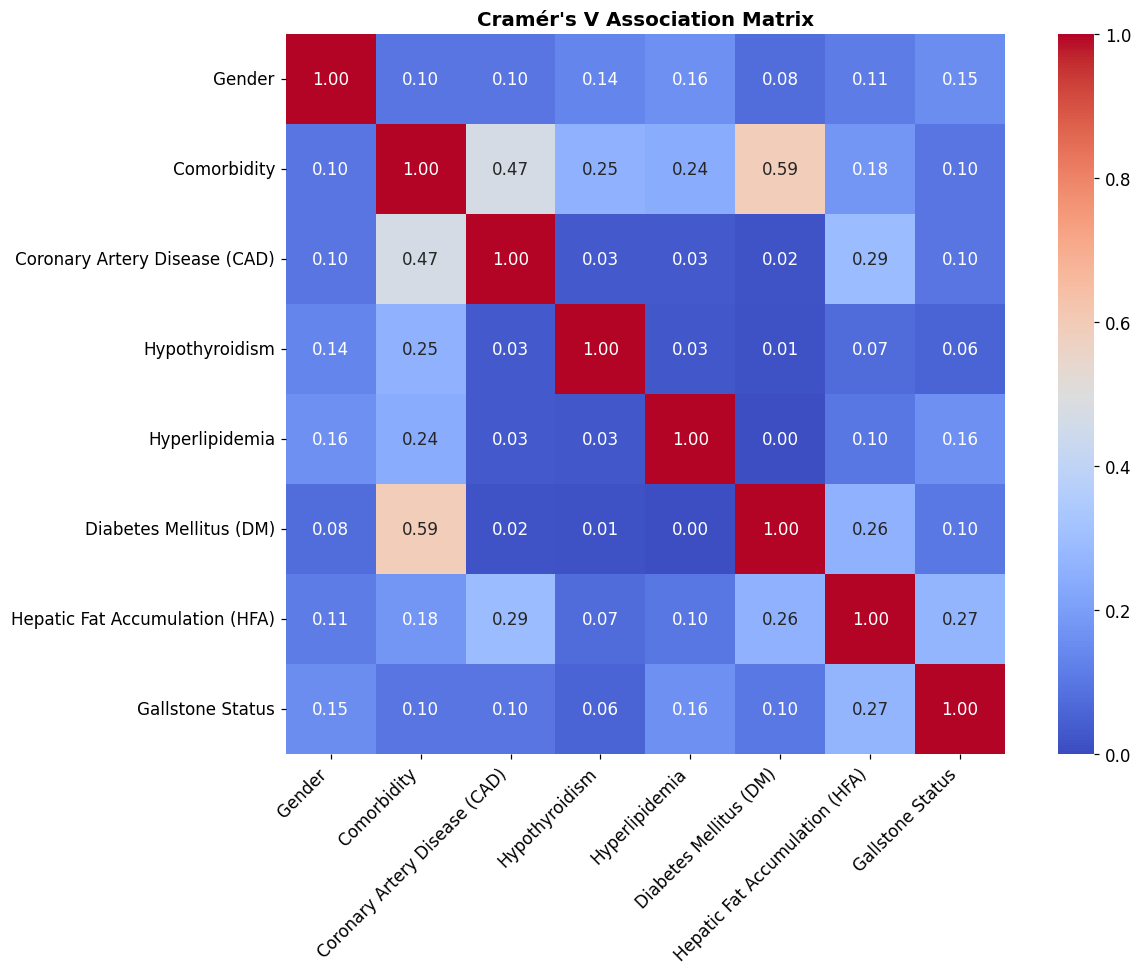

In [ ]:
plt.figure(figsize=(12, 9))

sns.heatmap(
  cramers_matrix,
  annot=True,
  fmt='.2f',
  cmap='coolwarm',
  vmin=0,
  vmax=1,
  square=True
)

plt.title("Cramér's V Association Matrix")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
save_fig('eda_05_cramers_v')

In [ ]:
# Menghilangkan Gallstone Status dari cat_cols
cat_cols = [col for col in cat_cols if col != 'Gallstone Status']

### Hasil EDA:


## Data Preprocessing


Data Preprocessing dilakukan dengan tahapan sebagai berikut.
1. Membagi DataFrame menjadi Train Set dan Test Set
1. Pembersihan Outlier (Outlier Removal & Capping)
1. Transformasi Distribusi & Transformasi Log
3. Pembersihan Multikolinearitas (Analisis Korelasi & VIF Filter)
4. Encoding & Feature Scaling
5. Seleksi Fitur Berbasis SHAP

### `obesity` feature cleaning

In [ ]:
df.loc[df['Obesity (%)'] > 200, 'Obesity (%)'] = np.nan

### Data Splitting

In [ ]:
X = df.drop(columns=['Gallstone Status'])
y = df['Gallstone Status']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
  X, y,
  test_size=0.2,
  random_state=42,
  stratify=y
)

In [ ]:
X_train_processed = X_train.copy()
X_test_processed = X_test.copy()

In [ ]:
medians_num = X_train_processed[num_cols].median()
X_train_processed[num_cols] = X_train_processed[num_cols].fillna(medians_num)
X_test_processed[num_cols] = X_test_processed[num_cols].fillna(medians_num)

### Outlier Cleaning

In [ ]:
# Capping berdasarkan IQR data training
capping_summary = []

for col in num_cols:
  Q1 = X_train_processed[col].quantile(0.25)
  Q3 = X_train_processed[col].quantile(0.75)
  IQR = Q3 - Q1

  lower = Q1 - 1.5 * IQR
  upper = Q3 + 1.5 * IQR

  outliers_train = (
    (X_train_processed[col] < lower) |
    (X_train_processed[col] > upper)
  ).sum()

  outliers_test = (
    (X_test_processed[col] < lower) |
    (X_test_processed[col] > upper)
  ).sum()

  capping_summary.append({
    'Feature': col,
    'Lower Bound': lower,
    'Upper Bound': upper,
    'Remaining Outliers Train': outliers_train,
    'Remaining Outliers Test': outliers_test
  })

display(pd.DataFrame(capping_summary))

,Feature,Lower Bound,Upper Bound,Remaining Outliers Train,Remaining Outliers Test
0,Age,11.0000,83.0000,2,0
1,Height,135.0000,199.0000,0,0
2,Weight,37.2750,122.6750,2,0
3,Body Mass Index (BMI),15.2500,41.6500,5,0
4,Total Body Water (TBW),14.6250,66.4250,1,0
5,Extracellular Water (ECW),7.9000,26.3000,1,0
6,Intracellular Water (ICW),6.3750,40.5750,1,0
7,Extracellular Fluid/Total Body Water (ECF/TBW),34.1875,49.8875,5,2
8,Total Body Fat Ratio (TBFR) (%),2.7725,54.1125,0,0
9,Lean Mass (LM) (%),45.9275,97.1075,0,0


In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

class IQRCapper(BaseEstimator, TransformerMixin):
    def __init__(self, cols, k=1.5):
        self.cols, self.k = cols, k
    def fit(self, X, y=None):
        q1, q3 = X[self.cols].quantile(0.25), X[self.cols].quantile(0.75)
        iqr = q3 - q1
        self.lower_, self.upper_ = q1 - self.k*iqr, q3 + self.k*iqr
        return self
    def transform(self, X):
        X = X.copy()
        X[self.cols] = X[self.cols].clip(lower=self.lower_, upper=self.upper_, axis=1)
        return X

cap_cols = [c for c in num_cols if c != 'C-Reactive Protein (CRP)']

# Fit hanya pada train, lalu terapkan ke train dan test
capper = IQRCapper(cap_cols).fit(X_train_processed)

# Ringkasan (sebelum capping)
b_tr = ((X_train_processed[cap_cols] < capper.lower_) | (X_train_processed[cap_cols] > capper.upper_)).sum()
b_te = ((X_test_processed[cap_cols] < capper.lower_) | (X_test_processed[cap_cols] > capper.upper_)).sum()

X_train_processed = capper.transform(X_train_processed)
X_test_processed = capper.transform(X_test_processed)

capping_df = pd.DataFrame({
    'Lower Bound': capper.lower_, 'Upper Bound': capper.upper_,
    'Train Outliers (Before)': b_tr, 'Test Outliers (Before)': b_te
})
display(capping_df)

,Lower Bound,Upper Bound,Train Outliers (Before),Test Outliers (Before)
Age,11.0000,83.0000,2,0
Height,135.0000,199.0000,0,0
Weight,37.2750,122.6750,2,0
Body Mass Index (BMI),15.2500,41.6500,5,0
Total Body Water (TBW),14.6250,66.4250,1,0
Extracellular Water (ECW),7.9000,26.3000,1,0
Intracellular Water (ICW),6.3750,40.5750,1,0
Extracellular Fluid/Total Body Water (ECF/TBW),34.1875,49.8875,5,2
Total Body Fat Ratio (TBFR) (%),2.7725,54.1125,0,0
Lean Mass (LM) (%),45.9275,97.1075,0,0


### Transformasi Distribusi & Normalisasi Log

In [ ]:
# Transformasi Log
skewed_cols = [c for c in num_cols if X_train_processed[c].skew() > 0.5]   # setelah capping
log_cols = [c for c in skewed_cols if (X_train_processed[c].dropna() >= 0).all()]

X_train_processed[log_cols] = np.log1p(
  X_train_processed[log_cols]
)

X_test_processed[log_cols] = np.log1p(
  X_test_processed[log_cols]
)

print("Fitur right-skewed:", skewed_cols)
print("Fitur yang ditransformasi log:", log_cols)

Fitur right-skewed: ['Obesity (%)', 'Glucose', 'High Density Lipoprotein (HDL)', 'Triglyceride', 'Aspartat Aminotransferaz (AST)', 'Alanin Aminotransferaz (ALT)', 'Creatinine', 'C-Reactive Protein (CRP)']
Fitur yang ditransformasi log: ['Obesity (%)', 'Glucose', 'High Density Lipoprotein (HDL)', 'Triglyceride', 'Aspartat Aminotransferaz (AST)', 'Alanin Aminotransferaz (ALT)', 'Creatinine', 'C-Reactive Protein (CRP)']


### Multikolinearitas Cleaning

In [ ]:
# Analisis Korelasi Fitur
corr_processed = X_train_processed[num_cols].corr()

# Mencari pasangan fitur dengan korelasi > 0.95
upper = corr_processed.abs().where(
    np.triu(np.ones(corr_processed.shape), k=1).astype(bool)
)

correlation_pairs = []

for col in upper.columns:
  for row in upper.index:
    value = upper.loc[row, col]

    if pd.notna(value) and value > 0.95:
      correlation_pairs.append({
        'Feature 1': row,
        'Feature 2': col,
        'Correlation': value
      })

correlation_df = pd.DataFrame(
  correlation_pairs,
  columns=['Feature 1', 'Feature 2', 'Correlation']
)

print("Pasangan fitur dengan korelasi absolut > 0.95:")
display(correlation_df)

Pasangan fitur dengan korelasi absolut > 0.95:


,Feature 1,Feature 2,Correlation
0,Total Body Fat Ratio (TBFR) (%),Lean Mass (LM) (%),0.997703
1,Intracellular Water (ICW),Muscle Mass (MM),0.951990


In [ ]:
def compute_vif(d):
    d = d.loc[:, d.nunique() > 1]
    dc = add_constant(d)
    return pd.DataFrame({
        'Feature': d.columns,
        'VIF': [variance_inflation_factor(dc.values, i + 1) for i in range(d.shape[1])]
    }).sort_values('VIF', ascending=False).reset_index(drop=True)

vif_df = compute_vif(X_train_processed[num_cols])
print("Fitur dengan VIF > 10:")
display(vif_df[vif_df['VIF'] > 10])

Fitur dengan VIF > 10:


,Feature,VIF
0,Total Body Fat Ratio (TBFR) (%),293.388083
1,Lean Mass (LM) (%),262.448342
2,Weight,130.725128
3,Extracellular Water (ECW),90.448211
4,Body Mass Index (BMI),80.045267
5,Height,47.443830
6,Visceral Fat Area (VFA),43.628444
7,Intracellular Water (ICW),34.709099
8,Muscle Mass (MM),33.660129
9,Total Body Water (TBW),25.997750


In [ ]:
# Fitur dari analisis korelasi
corr_features = set()

for _, row in correlation_df.iterrows():
  corr_features.add(row['Feature 1'])
  corr_features.add(row['Feature 2'])

# Fitur dari analisis VIF
vif_features = set(
  vif_df.loc[vif_df['VIF'] > 10, 'Feature']
)

# Gabungan kandidat fitur
candidate_features = corr_features | vif_features

print("Kandidat fitur dari korelasi:", sorted(corr_features))
print("Kandidat fitur dari VIF:", sorted(vif_features))
print("Gabungan kandidat fitur:", sorted(candidate_features))

Kandidat fitur dari korelasi: ['Intracellular Water (ICW)', 'Lean Mass (LM) (%)', 'Muscle Mass (MM)', 'Total Body Fat Ratio (TBFR) (%)']
Kandidat fitur dari VIF: ['Body Mass Index (BMI)', 'Extracellular Fluid/Total Body Water (ECF/TBW)', 'Extracellular Water (ECW)', 'Height', 'Intracellular Water (ICW)', 'Lean Mass (LM) (%)', 'Muscle Mass (MM)', 'Total Body Fat Ratio (TBFR) (%)', 'Total Body Water (TBW)', 'Total Fat Content (TFC)', 'Visceral Fat Area (VFA)', 'Visceral Fat Rating (VFR)', 'Weight']
Gabungan kandidat fitur: ['Body Mass Index (BMI)', 'Extracellular Fluid/Total Body Water (ECF/TBW)', 'Extracellular Water (ECW)', 'Height', 'Intracellular Water (ICW)', 'Lean Mass (LM) (%)', 'Muscle Mass (MM)', 'Total Body Fat Ratio (TBFR) (%)', 'Total Body Water (TBW)', 'Total Fat Content (TFC)', 'Visceral Fat Area (VFA)', 'Visceral Fat Rating (VFR)', 'Weight']


In [ ]:
def drop_by_vif(d, threshold=10):
    d, dropped = d.copy(), []
    while d.shape[1] > 1:
        v = compute_vif(d)
        if v.loc[0, 'VIF'] <= threshold:
            break
        dropped.append((v.loc[0, 'Feature'], round(v.loc[0, 'VIF'], 1)))
        d = d.drop(columns=v.loc[0, 'Feature'])
    return d.columns.tolist(), dropped

kept_num, dropped = drop_by_vif(X_train_processed[num_cols], threshold=10)
features_to_drop = [c for c in num_cols if c not in kept_num]

print("Dibuang (urutan, VIF):", [(f, float(v)) for f, v in dropped])
print("VIF maks setelah drop:", round(float(compute_vif(X_train_processed[kept_num])['VIF'].max()), 2))

X_train_processed.drop(columns=features_to_drop, inplace=True, errors='ignore')
X_test_processed.drop(columns=features_to_drop, inplace=True, errors='ignore')

print("X_train:", X_train_processed.shape)
print("X_test:", X_test_processed.shape)

Dibuang (urutan, VIF): [('Total Body Fat Ratio (TBFR) (%)', 293.4), ('Weight', 129.7), ('Extracellular Water (ECW)', 88.3), ('Visceral Fat Area (VFA)', 41.3), ('Body Mass Index (BMI)', 40.3), ('Muscle Mass (MM)', 31.6), ('Lean Mass (LM) (%)', 18.5), ('Intracellular Water (ICW)', 10.9)]
VIF maks setelah drop: 8.06
X_train: (255, 30)
X_test: (64, 30)


### Encoding & Feature Scaling

In [ ]:
# Fitur kategorikal ordinal (bertingkat) -> Ordinal Encoder
ordinal_cols = [
  'Hepatic Fat Accumulation (HFA)',
  'Comorbidity'
]

# Fitur kategorikal biner -> indikator biner 0/1
# (OneHotEncoder(drop='if_binary') menghasilkan satu kolom 0/1 per fitur biner,
#  sehingga tidak ada penambahan jumlah kolom)
binary_cols = [col for col in cat_cols if col not in ordinal_cols]

In [ ]:
# Encoder: biner (indikator 0/1) dan ordinal
binary_encoder = OneHotEncoder(
  drop='if_binary',
  handle_unknown='ignore',
  sparse_output=False
)

ordinal_encoder = OrdinalEncoder(
  handle_unknown='use_encoded_value',
  unknown_value=-1
)

# Gabungkan proses encoding
transformers = []

if binary_cols:
  transformers.append(('binary', binary_encoder, binary_cols))

if ordinal_cols:
  transformers.append(('ordinal', ordinal_encoder, ordinal_cols))

encoder = ColumnTransformer(
  transformers=transformers,
  remainder='passthrough',
  verbose_feature_names_out=False
)

# Fit pada training, lalu transform training dan testing
X_train_encoded = encoder.fit_transform(X_train_processed)
X_test_encoded = encoder.transform(X_test_processed)

# Ambil nama fitur hasil encoding
feature_names = encoder.get_feature_names_out()

# Ubah hasil menjadi DataFrame
X_train_processed = pd.DataFrame(
  X_train_encoded,
  columns=feature_names,
  index=X_train_processed.index
)

X_test_processed = pd.DataFrame(
  X_test_encoded,
  columns=feature_names,
  index=X_test_processed.index
)

print("X_train:", X_train_processed.shape)
print("X_test:", X_test_processed.shape)

print("\nFitur setelah encoding:")
print(X_train_processed.columns.tolist())

X_train: (255, 30)
X_test: (64, 30)

Fitur setelah encoding:
['Gender_1', 'Coronary Artery Disease (CAD)_1', 'Hypothyroidism_1', 'Hyperlipidemia_1', 'Diabetes Mellitus (DM)_1', 'Hepatic Fat Accumulation (HFA)', 'Comorbidity', 'Age', 'Height', 'Total Body Water (TBW)', 'Extracellular Fluid/Total Body Water (ECF/TBW)', 'Body Protein Content (Protein) (%)', 'Visceral Fat Rating (VFR)', 'Bone Mass (BM)', 'Obesity (%)', 'Total Fat Content (TFC)', 'Visceral Muscle Area (VMA) (Kg)', 'Glucose', 'Total Cholesterol (TC)', 'Low Density Lipoprotein (LDL)', 'High Density Lipoprotein (HDL)', 'Triglyceride', 'Aspartat Aminotransferaz (AST)', 'Alanin Aminotransferaz (ALT)', 'Alkaline Phosphatase (ALP)', 'Creatinine', 'Glomerular Filtration Rate (GFR)', 'C-Reactive Protein (CRP)', 'Hemoglobin (HGB)', 'Vitamin D']


In [ ]:
# Memperbarui num_cols agar hanya berisi fitur numerik yang masih ada di DataFrame setelah preprocessing
num_cols = [col for col in num_cols if col in X_train_processed.columns]

# Normalisasi Data
scaler = StandardScaler()

X_train_processed[num_cols] = scaler.fit_transform(
  X_train_processed[num_cols]
)

X_test_processed[num_cols] = scaler.transform(
  X_test_processed[num_cols]
)

print("X_train:", X_train_processed.shape)
print("X_test:", X_test_processed.shape)

X_train: (255, 30)
X_test: (64, 30)


### SHAP Feature Selection

25 Fitur Teratas Berdasarkan SHAP:


,Mean |SHAP|
Feature,
C-Reactive Protein (CRP),1.7458
Vitamin D,0.7569
Extracellular Fluid/Total Body Water (ECF/TBW),0.5476
Obesity (%),0.5276
Body Protein Content (Protein) (%),0.4801
Total Fat Content (TFC),0.4620
Aspartat Aminotransferaz (AST),0.4183
Bone Mass (BM),0.4032
Visceral Muscle Area (VMA) (Kg),0.3375


[Gambar tersimpan] figures/shap_01_seleksi_25_fitur.png


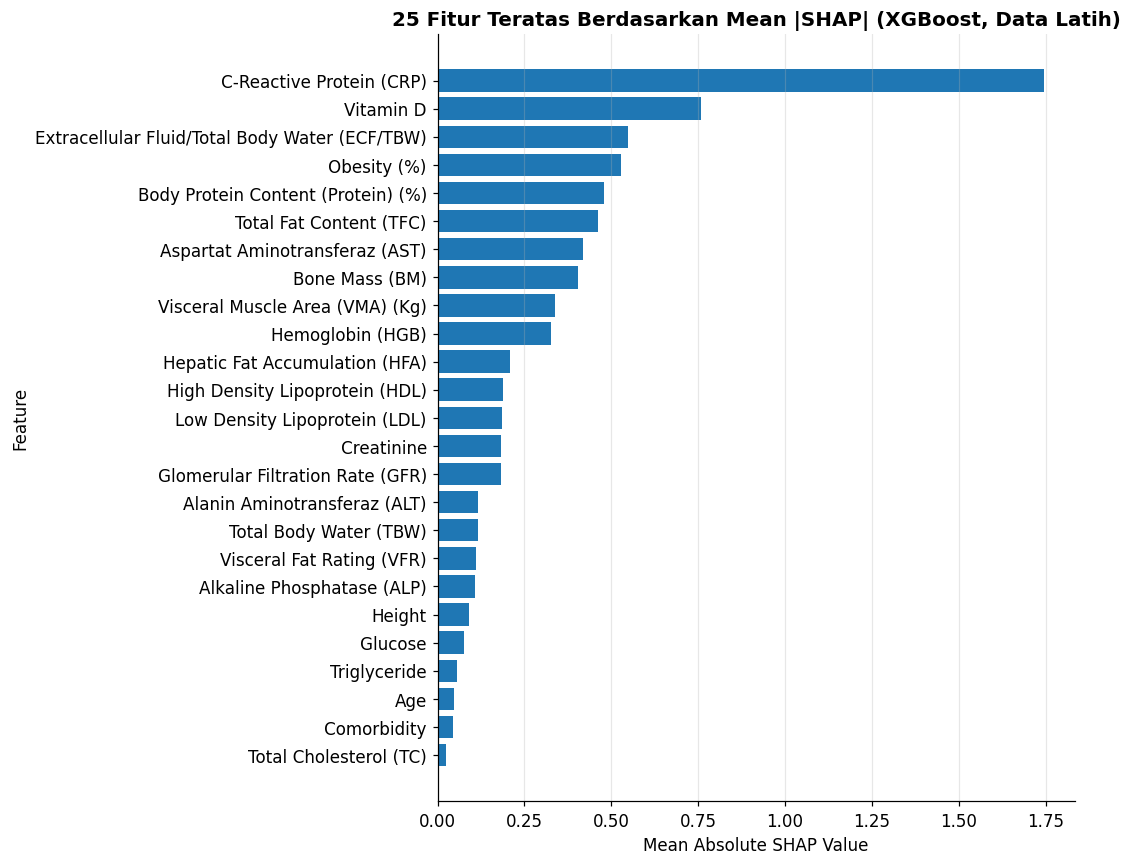

In [ ]:
xgb_model = XGBClassifier(
  n_estimators=200,
  max_depth=6,
  learning_rate=0.1,
  random_state=42,
  eval_metric='logloss'
)

xgb_model.fit(X_train_processed, y_train)

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_train_processed)

# Menangani format SHAP untuk klasifikasi biner
if isinstance(shap_values, list):
  shap_values = shap_values[-1]

if getattr(shap_values, 'ndim', 0) == 3:
  shap_values = shap_values[:, :, -1]

# Menghitung rata-rata absolut nilai SHAP setiap fitur
mean_abs_shap = abs(shap_values).mean(axis=0)

shap_importance = pd.DataFrame({
  'Feature': X_train_processed.columns,
  'Mean |SHAP|': mean_abs_shap
}).sort_values(
  by='Mean |SHAP|',
  ascending=False
).reset_index(drop=True)

# Mengambil 25 fitur teratas
top_25_features = shap_importance.head(25)

print("25 Fitur Teratas Berdasarkan SHAP:")
save_table(top_25_features.set_index('Feature'), 'seleksi_shap_25_fitur')

# Visualisasi 25 fitur teratas
plt.figure(figsize=(10, 8))
plt.grid(axis='x', alpha=0.3)
plt.barh(
  top_25_features['Feature'][::-1],
  top_25_features['Mean |SHAP|'][::-1]
)
plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Feature')
plt.title('25 Fitur Teratas Berdasarkan Mean |SHAP| (XGBoost, Data Latih)')
plt.tight_layout()
save_fig('shap_01_seleksi_25_fitur')

## Modeling

Rancangan pemodelan (keputusan final):

| Komponen | Keterangan |
|---|---|
| Model dasar (7) | Random Forest, Extra Trees, XGBoost, Gradient Boosting, LightGBM, Logistic Regression, SVM RBF |
| Pemilihan Top-3 | Peringkat **ROC AUC validasi silang pada data latih** (5-fold × 3 ulangan); pemecah seri: **Brier Score** terendah. ROC AUC hanya untuk seleksi, bukan metrik evaluasi |
| Ensemble (3 jenis × 2 varian = 6) | **Hard Voting**, **Soft Voting** (bobot = F1 validasi silang, kalibrasi sigmoid + *threshold tuning*), **Stacking** (prediksi OOF, meta-learner Logistic Regression) |
| Varian | **Top-3** (3 model teratas) vs **7 Model** (semua model dasar) |
| Metrik | Accuracy, Precision, Recall, F1-score, Brier Score, Decision Curve Analysis (DCA) |
| XAI | SHAP (global) dan LIME (lokal) pada ensemble berbasis probabilitas terbaik |

Semua keputusan (Top-3, bobot, kalibrasi, *threshold*) ditentukan **hanya dari data latih**.

In [ ]:
# Ambil nama 25 fitur teratas dari hasil SHAP
top_features = top_25_features['Feature'].tolist()

# Gunakan fitur yang sama untuk training dan testing
X_train_model = X_train_processed[top_features].copy()
X_test_model = X_test_processed[top_features].copy()

# Pastikan target berbentuk Series
y_train_model = pd.Series(y_train, index=X_train_model.index).squeeze()
y_test_model = pd.Series(y_test, index=X_test_model.index).squeeze()

# Pastikan target klasifikasi biner
if y_train_model.nunique() != 2:
    raise ValueError("Kode ini ditujukan untuk klasifikasi biner.")

# Tangani nilai tak hingga dan nilai kosong jika ada
X_train_model = X_train_model.replace([np.inf, -np.inf], np.nan)
X_test_model = X_test_model.replace([np.inf, -np.inf], np.nan)

# Imputasi menggunakan median dari data training
medians = X_train_model.median()

X_train_model = X_train_model.fillna(medians)
X_test_model = X_test_model.fillna(medians)

# XGBoost dan LightGBM memerlukan target numerik untuk klasifikasi biner
classes = sorted(y_train_model.unique())
class_mapping = {label: i for i, label in enumerate(classes)}

y_train_bin = y_train_model.map(class_mapping).astype(int)
y_test_bin = y_test_model.map(class_mapping)

if y_test_bin.isna().any():
    raise ValueError("Label pada data testing tidak ditemukan di data training.")

y_test_bin = y_test_bin.astype(int)

print("Jumlah fitur:", X_train_model.shape[1])
print("Jumlah data training:", X_train_model.shape[0])
print("Jumlah data testing:", X_test_model.shape[0])
print("Pemetaan kelas:", class_mapping)

Jumlah fitur: 25
Jumlah data training: 255
Jumlah data testing: 64
Pemetaan kelas: {np.int64(0): 0, np.int64(1): 1}


### Model Dasar (7 Model)

In [ ]:
models = {
  'Random Forest': RandomForestClassifier(
      n_estimators=200,
      random_state=42,
      n_jobs=-1,
      class_weight='balanced'
  ),

  'XGBoost': XGBClassifier(
      n_estimators=200,
      max_depth=4,
      learning_rate=0.05,
      subsample=0.8,
      colsample_bytree=0.8,
      eval_metric='logloss',
      random_state=42,
      n_jobs=-1
  ),

  'Logistic Regression': LogisticRegression(
      max_iter=2000,
      class_weight='balanced',
      random_state=42
  ),

  'Gradient Boosting': GradientBoostingClassifier(
      n_estimators=150,
      learning_rate=0.05,
      max_depth=3,
      random_state=42
  ),

  'Extra Trees': ExtraTreesClassifier(
      n_estimators=200,
      random_state=42,
      n_jobs=-1,
      class_weight='balanced'
  ),

  'LightGBM': LGBMClassifier(
      n_estimators=200,
      learning_rate=0.05,
      verbosity=-1,
      random_state=42,
      n_jobs=-1,
      class_weight='balanced'
  ),

  'SVM RBF': SVC(
      kernel='rbf',
      probability=True,
      class_weight='balanced',
      random_state=42
  )
}

### Evaluasi Model Dasar dan Penentuan Top-3

Peringkat memakai **rerata ROC AUC validasi silang pada data latih** (dibulatkan 3 desimal), seri dipecahkan dengan **Brier Score** terendah. Hasil pada data uji hanya sebagai pembanding (baseline), tidak dipakai untuk memilih model.

In [ ]:
assert POSITIVE_CLASS == 1  # scorer 'f1' bawaan sklearn memakai pos_label=1

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

def test_metrics(name, y_true, y_pred, y_prob=None):
  """Accuracy, Precision, Recall, F1, Brier. y_prob=None (Hard Voting) -> Brier = NaN."""
  return {
    'Model': name,
    'Accuracy':    accuracy_score(y_true, y_pred),
    'Precision':   precision_score(y_true, y_pred, pos_label=POSITIVE_CLASS, zero_division=0),
    'Recall':      recall_score(y_true, y_pred, pos_label=POSITIVE_CLASS, zero_division=0),
    'F1-score':    f1_score(y_true, y_pred, pos_label=POSITIVE_CLASS, zero_division=0),
    'Brier Score': brier_score_loss(y_true, y_prob, pos_label=POSITIVE_CLASS)
                   if y_prob is not None else np.nan
  }

def cv_scores(estimator, has_proba=True, with_auc=False):
  """F1 dan Brier (opsional ROC AUC untuk seleksi) validasi silang berulang pada DATA LATIH."""
  scoring = {'f1': 'f1'}
  if has_proba:
    scoring['brier'] = 'neg_brier_score'
  if with_auc:
    scoring['auc'] = 'roc_auc'
  r = cross_validate(clone(estimator), X_train_model, y_train_bin,
                     cv=cv, scoring=scoring, n_jobs=1)
  out = {
    'CV F1':     r['test_f1'].mean(),
    'CV F1 Std': r['test_f1'].std(),
    'CV Brier':  -r['test_brier'].mean() if has_proba else np.nan
  }
  if with_auc:
    out['CV ROC AUC']     = r['test_auc'].mean()
    out['CV ROC AUC Std'] = r['test_auc'].std()
  return out

fitted_base, base_rows = {}, []
for name, model in models.items():
  print(f'Melatih {name}...')
  cvr = cv_scores(model, with_auc=True)
  model.fit(X_train_model, y_train_bin)
  fitted_base[name] = model
  row = test_metrics(name, y_test_bin, model.predict(X_test_model),
                     model.predict_proba(X_test_model)[:, 1])
  base_rows.append({**cvr, **row})

base_df = pd.DataFrame(base_rows)
base_df['_auc_rank'] = base_df['CV ROC AUC'].round(3)
base_df = (base_df.sort_values(['_auc_rank', 'CV Brier'], ascending=[False, True])
                  .drop(columns='_auc_rank').reset_index(drop=True))
base_df.insert(0, 'Peringkat', range(1, len(base_df) + 1))
base_df = base_df[['Peringkat', 'Model', 'CV ROC AUC', 'CV ROC AUC Std', 'CV F1', 'CV F1 Std', 'CV Brier',
                   'Accuracy', 'Precision', 'Recall', 'F1-score', 'Brier Score']]

top3  = base_df['Model'].head(3).tolist()
cv_f1 = base_df.set_index('Model')['CV F1'].to_dict()   # bobot Soft Voting tetap memakai F1 validasi silang

print('\nTop-3 model dasar (berdasarkan ROC AUC validasi silang data latih):', top3)
save_table(base_df.set_index('Peringkat'), 'm1_model_dasar')

Melatih Random Forest...
Melatih XGBoost...
Melatih Logistic Regression...
Melatih Gradient Boosting...
Melatih Extra Trees...
Melatih LightGBM...
Melatih SVM RBF...

Top-3 model dasar (berdasarkan ROC AUC validasi silang data latih): ['XGBoost', 'Random Forest', 'Extra Trees']


,Model,CV ROC AUC,CV ROC AUC Std,CV F1,CV F1 Std,CV Brier,Accuracy,Precision,Recall,F1-score,Brier Score
Peringkat,,,,,,,,,,,
1,XGBoost,0.8509,0.0503,0.7559,0.0577,0.1629,0.8594,0.8710,0.8438,0.8571,0.1228
2,Random Forest,0.8488,0.0476,0.7654,0.0557,0.1678,0.7812,0.8214,0.7188,0.7667,0.1558
3,Extra Trees,0.8467,0.0436,0.7497,0.0531,0.1697,0.7969,0.8519,0.7188,0.7797,0.1562
4,SVM RBF,0.8396,0.0411,0.7555,0.0501,0.1644,0.7969,0.8276,0.7500,0.7869,0.1291
5,Gradient Boosting,0.8363,0.0637,0.7652,0.0656,0.1671,0.7812,0.8000,0.7500,0.7742,0.1575
6,Logistic Regression,0.8354,0.0489,0.7446,0.0540,0.1636,0.8125,0.8571,0.7500,0.8000,0.1190
7,LightGBM,0.8275,0.0522,0.7396,0.0649,0.1849,0.8438,0.8438,0.8438,0.8438,0.1269


,Model,CV ROC AUC,CV ROC AUC Std,CV F1,CV F1 Std,CV Brier,Accuracy,Precision,Recall,F1-score,Brier Score
Peringkat,,,,,,,,,,,
1,XGBoost,0.8509,0.0503,0.7559,0.0577,0.1629,0.8594,0.8710,0.8438,0.8571,0.1228
2,Random Forest,0.8488,0.0476,0.7654,0.0557,0.1678,0.7812,0.8214,0.7188,0.7667,0.1558
3,Extra Trees,0.8467,0.0436,0.7497,0.0531,0.1697,0.7969,0.8519,0.7188,0.7797,0.1562
4,SVM RBF,0.8396,0.0411,0.7555,0.0501,0.1644,0.7969,0.8276,0.7500,0.7869,0.1291
5,Gradient Boosting,0.8363,0.0637,0.7652,0.0656,0.1671,0.7812,0.8000,0.7500,0.7742,0.1575
6,Logistic Regression,0.8354,0.0489,0.7446,0.0540,0.1636,0.8125,0.8571,0.7500,0.8000,0.1190
7,LightGBM,0.8275,0.0522,0.7396,0.0649,0.1849,0.8438,0.8438,0.8438,0.8438,0.1269


[Gambar tersimpan] figures/model_01_peringkat_model_dasar.png


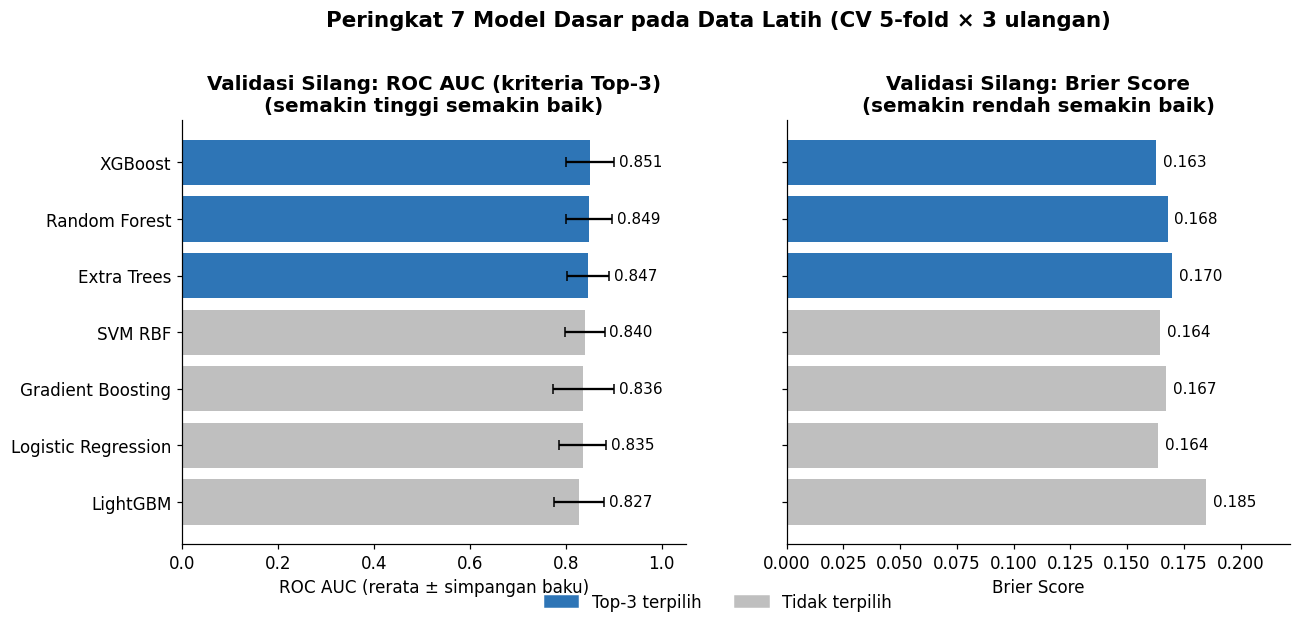

In [ ]:
# Visualisasi: peringkat model dasar (siap untuk laporan)
order  = base_df.iloc[::-1]
colors = [VARIANT_COLORS['Top-3'] if m in top3 else '#BFBFBF' for m in order['Model']]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

axes[0].barh(order['Model'], order['CV ROC AUC'], xerr=order['CV ROC AUC Std'], color=colors, capsize=3)
for y_, (v, s) in enumerate(zip(order['CV ROC AUC'], order['CV ROC AUC Std'])):
  axes[0].text(v + s + 0.01, y_, f'{v:.3f}', va='center', fontsize=10)
axes[0].set_xlim(0, 1.05)
axes[0].set_xlabel('ROC AUC (rerata ± simpangan baku)')
axes[0].set_title('Validasi Silang: ROC AUC (kriteria Top-3)\n(semakin tinggi semakin baik)')

axes[1].barh(order['Model'], order['CV Brier'], color=colors)
for y_, v in enumerate(order['CV Brier']):
  axes[1].text(v + 0.003, y_, f'{v:.3f}', va='center', fontsize=10)
axes[1].set_xlim(0, order['CV Brier'].max() * 1.2)
axes[1].set_xlabel('Brier Score')
axes[1].set_title('Validasi Silang: Brier Score\n(semakin rendah semakin baik)')

from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=VARIANT_COLORS['Top-3'], label='Top-3 terpilih'),
                    Patch(color='#BFBFBF', label='Tidak terpilih')],
           loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.04))
fig.suptitle('Peringkat 7 Model Dasar pada Data Latih (CV 5-fold × 3 ulangan)', fontsize=14, fontweight='bold', y=1.08)
save_fig('model_01_peringkat_model_dasar')

### Pembentukan 6 Konfigurasi Ensemble

| Ensemble | Mekanisme |
|---|---|
| **Hard Voting** | *Majority voting* label kelas dari seluruh model anggota. Tidak menghasilkan probabilitas, sehingga **tidak memiliki Brier Score dan DCA**. |
| **Soft Voting** | Rata-rata probabilitas berbobot (bobot = F1 validasi silang) → **kalibrasi sigmoid** → ***threshold tuning*** (memaksimalkan F1 pada prediksi *out-of-fold* data latih). |
| **Stacking** | Prediksi probabilitas *out-of-fold* (OOF, 5-fold) model anggota menjadi input meta-learner **Logistic Regression**. |

Setiap ensemble dibangun dalam dua varian: **Top-3** dan **7 Model**.

In [ ]:
def inner_cv(k):
  return StratifiedKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)

f1_scorer = make_scorer(f1_score, pos_label=POSITIVE_CLASS)

def build_ensembles(names, variant):
  """Bangun 3 ensemble dari daftar nama model dasar."""
  members = lambda: [(n, clone(models[n])) for n in names]
  weights = [cv_f1[n] for n in names]

  soft_core = VotingClassifier(members(), voting='soft', weights=weights, n_jobs=1)
  soft = TunedThresholdClassifierCV(
    CalibratedClassifierCV(soft_core, method='sigmoid', cv=inner_cv(3)),
    scoring=f1_scorer, response_method='predict_proba',
    thresholds=np.linspace(0.05, 0.95, 91), cv=inner_cv(3),
    refit=True, store_cv_results=True, random_state=RANDOM_STATE
  )
  return {
    f'Hard Voting ({variant})': dict(group='Hard Voting', variant=variant, has_proba=False,
        estimator=VotingClassifier(members(), voting='hard', n_jobs=1)),
    f'Soft Voting ({variant})': dict(group='Soft Voting', variant=variant, has_proba=True,
        estimator=soft),
    f'Stacking ({variant})':    dict(group='Stacking', variant=variant, has_proba=True,
        estimator=StackingClassifier(
          members(),
          final_estimator=LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
          stack_method='predict_proba', cv=inner_cv(5), n_jobs=1, passthrough=False))
  }

ens_specs = {}
ens_specs.update(build_ensembles(top3, 'Top-3'))
ens_specs.update(build_ensembles(list(models.keys()), '7 Model'))

fitted_ens, preds, probs, ens_rows = {}, {}, {}, []
for name, spec in ens_specs.items():
  print(f'Melatih & mengevaluasi {name}...')
  est = spec['estimator']
  cvr = cv_scores(est, spec['has_proba'])
  est.fit(X_train_model, y_train_bin)
  fitted_ens[name] = est

  preds[name] = est.predict(X_test_model)
  probs[name] = est.predict_proba(X_test_model)[:, 1] if spec['has_proba'] else None

  if spec['group'] == 'Soft Voting':
    thr = est.best_threshold_            # hasil threshold tuning (data latih)
  elif spec['group'] == 'Stacking':
    thr = 0.5
  else:
    thr = np.nan
  ens_rows.append({**test_metrics(name, y_test_bin, preds[name], probs[name]),
                   'Ensemble': spec['group'], 'Varian': spec['variant'],
                   'Threshold': thr, **cvr})

ensemble_df = pd.DataFrame(ens_rows)
ensemble_df['Ensemble'] = pd.Categorical(ensemble_df['Ensemble'], ENS_ORDER, ordered=True)
ensemble_df['Varian']   = pd.Categorical(ensemble_df['Varian'], ['Top-3', '7 Model'], ordered=True)
ensemble_df = ensemble_df.sort_values(['Ensemble', 'Varian']).reset_index(drop=True)
ens_cols = ['Model', 'Ensemble', 'Varian', 'Accuracy', 'Precision', 'Recall', 'F1-score',
            'Brier Score', 'Threshold', 'CV F1', 'CV F1 Std', 'CV Brier']
ensemble_df = ensemble_df[ens_cols]

print('\nHasil 6 ensemble pada data uji (n = 64). Brier Score kosong pada Hard Voting karena tidak ada probabilitas.')
save_table(ensemble_df.set_index('Model'), 'm2_hasil_6_ensemble')

Melatih & mengevaluasi Hard Voting (Top-3)...
Melatih & mengevaluasi Soft Voting (Top-3)...
Melatih & mengevaluasi Stacking (Top-3)...
Melatih & mengevaluasi Hard Voting (7 Model)...
Melatih & mengevaluasi Soft Voting (7 Model)...
Melatih & mengevaluasi Stacking (7 Model)...

Hasil 6 ensemble pada data uji (n = 64). Brier Score kosong pada Hard Voting karena tidak ada probabilitas.


,Ensemble,Varian,Accuracy,Precision,Recall,F1-score,Brier Score,Threshold,CV F1,CV F1 Std,CV Brier
Model,,,,,,,,,,,
Hard Voting (Top-3),Hard Voting,Top-3,0.7969,0.8276,0.7500,0.7869,NaN,NaN,0.7552,0.0533,NaN
Hard Voting (7 Model),Hard Voting,7 Model,0.8438,0.8438,0.8438,0.8438,NaN,NaN,0.7653,0.0607,NaN
Soft Voting (Top-3),Soft Voting,Top-3,0.7969,0.7714,0.8438,0.8060,0.1366,0.37,0.7698,0.0493,0.1593
Soft Voting (7 Model),Soft Voting,7 Model,0.8281,0.7692,0.9375,0.8451,0.1327,0.33,0.7694,0.0526,0.1567
Stacking (Top-3),Stacking,Top-3,0.8125,0.8333,0.7812,0.8065,0.1297,0.50,0.7630,0.0552,0.1595
Stacking (7 Model),Stacking,7 Model,0.8125,0.8333,0.7812,0.8065,0.1275,0.50,0.7660,0.0598,0.1601


,Ensemble,Varian,Accuracy,Precision,Recall,F1-score,Brier Score,Threshold,CV F1,CV F1 Std,CV Brier
Model,,,,,,,,,,,
Hard Voting (Top-3),Hard Voting,Top-3,0.7969,0.8276,0.7500,0.7869,NaN,NaN,0.7552,0.0533,NaN
Hard Voting (7 Model),Hard Voting,7 Model,0.8438,0.8438,0.8438,0.8438,NaN,NaN,0.7653,0.0607,NaN
Soft Voting (Top-3),Soft Voting,Top-3,0.7969,0.7714,0.8438,0.8060,0.1366,0.37,0.7698,0.0493,0.1593
Soft Voting (7 Model),Soft Voting,7 Model,0.8281,0.7692,0.9375,0.8451,0.1327,0.33,0.7694,0.0526,0.1567
Stacking (Top-3),Stacking,Top-3,0.8125,0.8333,0.7812,0.8065,0.1297,0.50,0.7630,0.0552,0.1595
Stacking (7 Model),Stacking,7 Model,0.8125,0.8333,0.7812,0.8065,0.1275,0.50,0.7660,0.0598,0.1601


### Visualisasi Evaluasi Ensemble

[Gambar tersimpan] figures/eval_01_metrik_klasifikasi.png


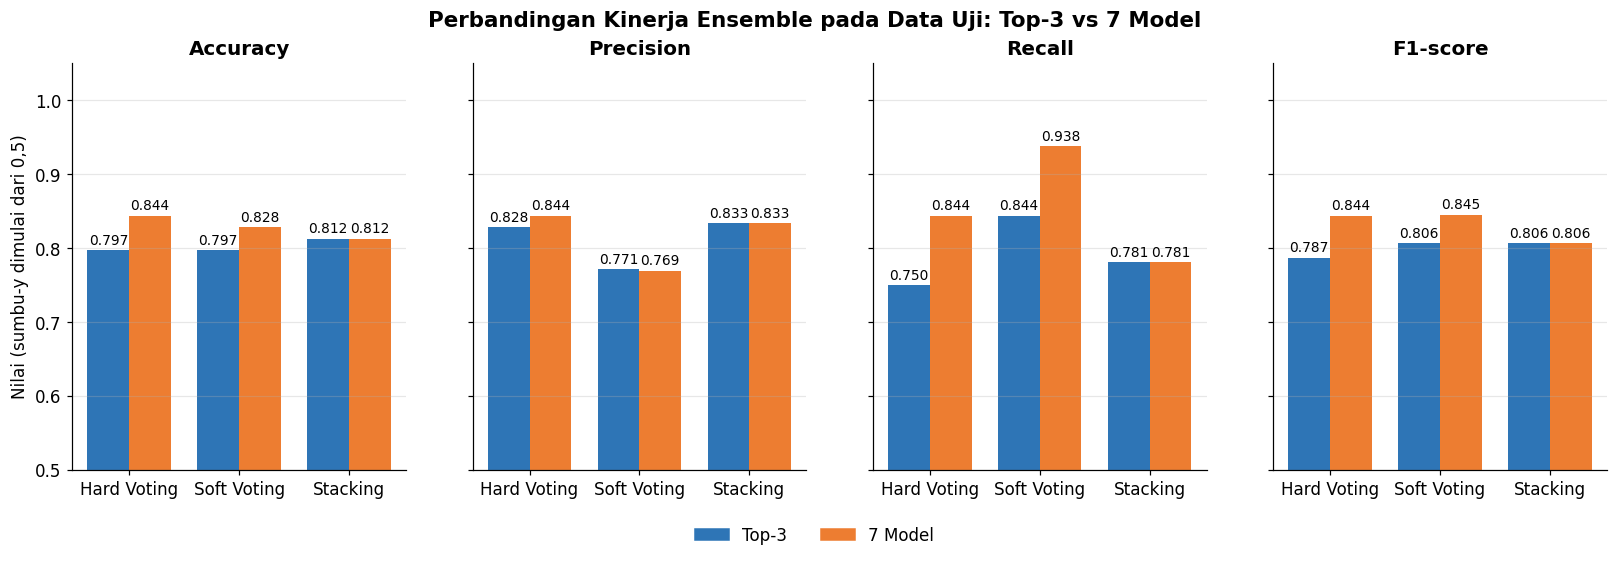

In [ ]:
# Gambar 1: Accuracy, Precision, Recall, F1 — Top-3 vs 7 Model
metrics4 = ['Accuracy', 'Precision', 'Recall', 'F1-score']
x, w = np.arange(len(ENS_ORDER)), 0.38
fig, axes = plt.subplots(1, 4, figsize=(18, 4.8), sharey=True)
for ax, m in zip(axes, metrics4):
  for k, var in enumerate(['Top-3', '7 Model']):
    vals = [ensemble_df[(ensemble_df['Ensemble'] == g) & (ensemble_df['Varian'] == var)][m].iloc[0] for g in ENS_ORDER]
    bars = ax.bar(x + (k - 0.5) * w, vals, w, label=var, color=VARIANT_COLORS[var])
    for b_, v in zip(bars, vals):
      ax.text(b_.get_x() + b_.get_width() / 2, v + 0.008, f'{v:.3f}', ha='center', fontsize=9)
  ax.set_xticks(x); ax.set_xticklabels(ENS_ORDER)
  ax.set_title(m); ax.set_ylim(0.5, 1.05)
  ax.grid(axis='y', alpha=0.3)
axes[0].set_ylabel('Nilai (sumbu-y dimulai dari 0,5)')
fig.legend(handles=[Patch(color=VARIANT_COLORS[v], label=v) for v in VARIANT_COLORS],
           loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.06))
fig.suptitle('Perbandingan Kinerja Ensemble pada Data Uji: Top-3 vs 7 Model', fontsize=14, fontweight='bold')
save_fig('eval_01_metrik_klasifikasi')

[Gambar tersimpan] figures/eval_02_interval_kepercayaan.png


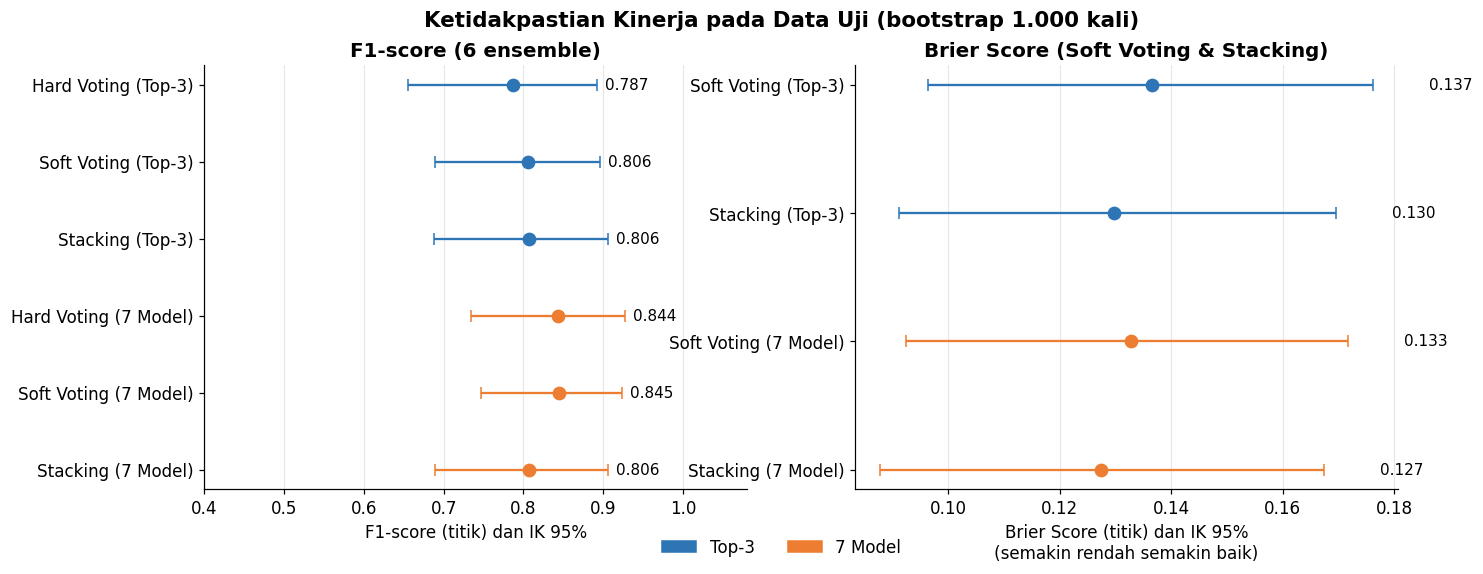

In [ ]:
# Gambar 2: F1-score dan Brier Score dengan interval kepercayaan 95% (bootstrap)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

def ci_plot(ax, metric, names, xlabel, title):
  for y_, n in enumerate(names[::-1]):
    var = ens_specs[n]['variant']
    obs = ensemble_df.set_index('Model').loc[n, metric]
    lo, hi = ci_df.loc[n, metric + '_lo'], ci_df.loc[n, metric + '_hi']
    ax.errorbar(obs, y_, xerr=[[max(obs - lo, 0)], [max(hi - obs, 0)]], fmt='o', capsize=4,
                color=VARIANT_COLORS[var], markersize=8)
    ax.text(hi + 0.01, y_, f'{obs:.3f}', va='center', fontsize=10)
  ax.set_yticks(range(len(names))); ax.set_yticklabels(names[::-1])
  ax.set_xlabel(xlabel); ax.set_title(title); ax.grid(axis='x', alpha=0.3)

all_names  = list(ens_specs.keys())
prob_names = [n for n in all_names if ens_specs[n]['has_proba']]
ci_plot(axes[0], 'F1-score', all_names, 'F1-score (titik) dan IK 95%', 'F1-score (6 ensemble)')
ci_plot(axes[1], 'Brier Score', prob_names, 'Brier Score (titik) dan IK 95%\n(semakin rendah semakin baik)', 'Brier Score (Soft Voting & Stacking)')
axes[0].set_xlim(0.4, 1.08)
fig.legend(handles=[Patch(color=VARIANT_COLORS[v], label=v) for v in VARIANT_COLORS],
           loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.04))
fig.suptitle('Ketidakpastian Kinerja pada Data Uji (bootstrap 1.000 kali)', fontsize=14, fontweight='bold')
save_fig('eval_02_interval_kepercayaan')

[Gambar tersimpan] figures/eval_03_confusion_matrix.png


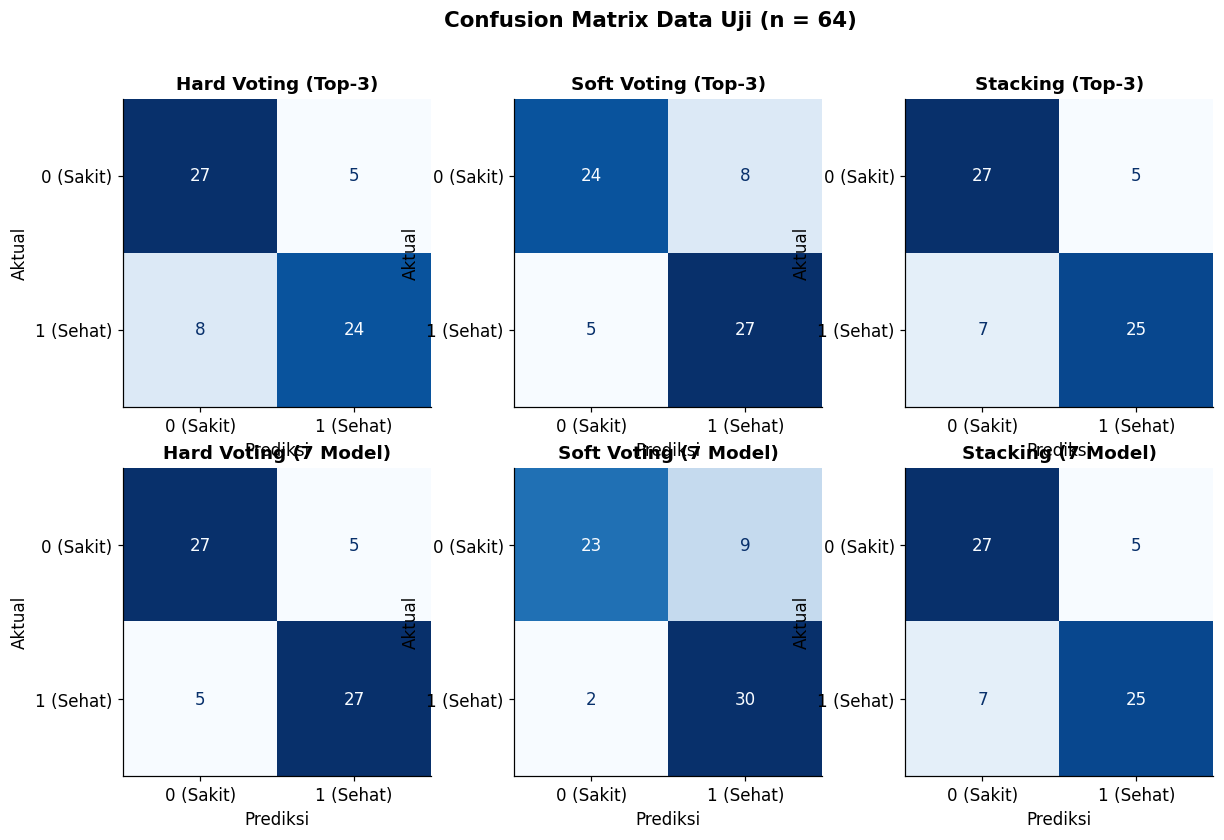

In [ ]:
# Gambar 3: Confusion matrix 6 ensemble (baris = varian, kolom = jenis ensemble)
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for r_, var in enumerate(['Top-3', '7 Model']):
  for c_, g in enumerate(ENS_ORDER):
    n = f'{g} ({var})'
    ConfusionMatrixDisplay.from_predictions(
      y_arr, preds[n], labels=[0, 1], display_labels=CLASS_LABELS,
      ax=axes[r_, c_], colorbar=False, cmap='Blues', values_format='d')
    axes[r_, c_].set_title(f'{g} ({var})', fontsize=12)
    axes[r_, c_].set_xlabel('Prediksi'); axes[r_, c_].set_ylabel('Aktual')
fig.suptitle('Confusion Matrix Data Uji (n = 64)', fontsize=14, fontweight='bold')
save_fig('eval_03_confusion_matrix')

## Explainable AI (XAI)

XAI diterapkan pada **satu ensemble berbasis probabilitas** (Soft Voting atau Stacking; Hard Voting tidak dapat dijelaskan lewat probabilitas). Model dipilih dengan aturan yang **tidak memakai data uji**: ensemble dengan **Brier Score validasi silang (data latih) terendah**.


In [ ]:
SHAP_BACKGROUND = 10    # jumlah pusat k-means sebagai data latar
SHAP_NSAMPLES   = 500   # sampel perturbasi per observasi (naikkan untuk hasil lebih halus, lebih lama)

cand = ensemble_df[ensemble_df['Brier Score'].notna()]
xai_name = cand.sort_values('CV Brier').iloc[0]['Model']
xai_model = fitted_ens[xai_name]
feature_list = X_train_model.columns.tolist()
print('Model untuk XAI (CV Brier terendah):', xai_name)

def predict_pos(data):
  return xai_model.predict_proba(pd.DataFrame(data, columns=feature_list))[:, 1]

background = shap.kmeans(X_train_model, SHAP_BACKGROUND)
explainer  = shap.KernelExplainer(predict_pos, background)
shap_vals  = np.array(explainer.shap_values(X_test_model, nsamples=SHAP_NSAMPLES, silent=True))
if shap_vals.ndim == 3:
  shap_vals = shap_vals[..., -1]

xai_importance = (pd.DataFrame({'Feature': feature_list, 'Mean |SHAP|': np.abs(shap_vals).mean(0)})
                  .sort_values('Mean |SHAP|', ascending=False).reset_index(drop=True))
save_table(xai_importance.set_index('Feature'), 'xai_shap_pentingnya_fitur', show=False)
display(xai_importance.head(10).round(4))

Model untuk XAI (CV Brier terendah): Soft Voting (7 Model)


,Feature,Mean |SHAP|
0,C-Reactive Protein (CRP),0.1689
1,Vitamin D,0.0862
2,Aspartat Aminotransferaz (AST),0.0481
3,Bone Mass (BM),0.0467
4,Extracellular Fluid/Total Body Water (ECF/TBW),0.0399
5,Obesity (%),0.0291
6,Visceral Muscle Area (VMA) (Kg),0.0260
7,Body Protein Content (Protein) (%),0.0250
8,Total Fat Content (TFC),0.0217
9,Hepatic Fat Accumulation (HFA),0.0165


[Gambar tersimpan] figures/xai_01_shap_summary_beeswarm.png


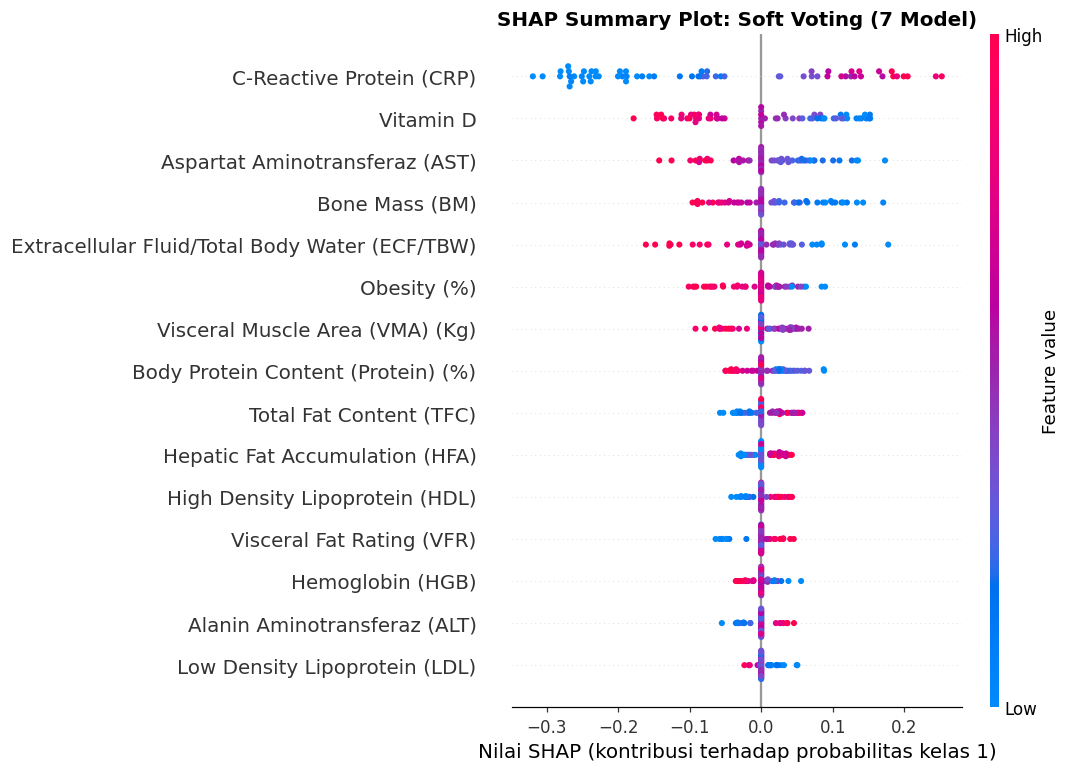

[Gambar tersimpan] figures/xai_02_shap_bar.png


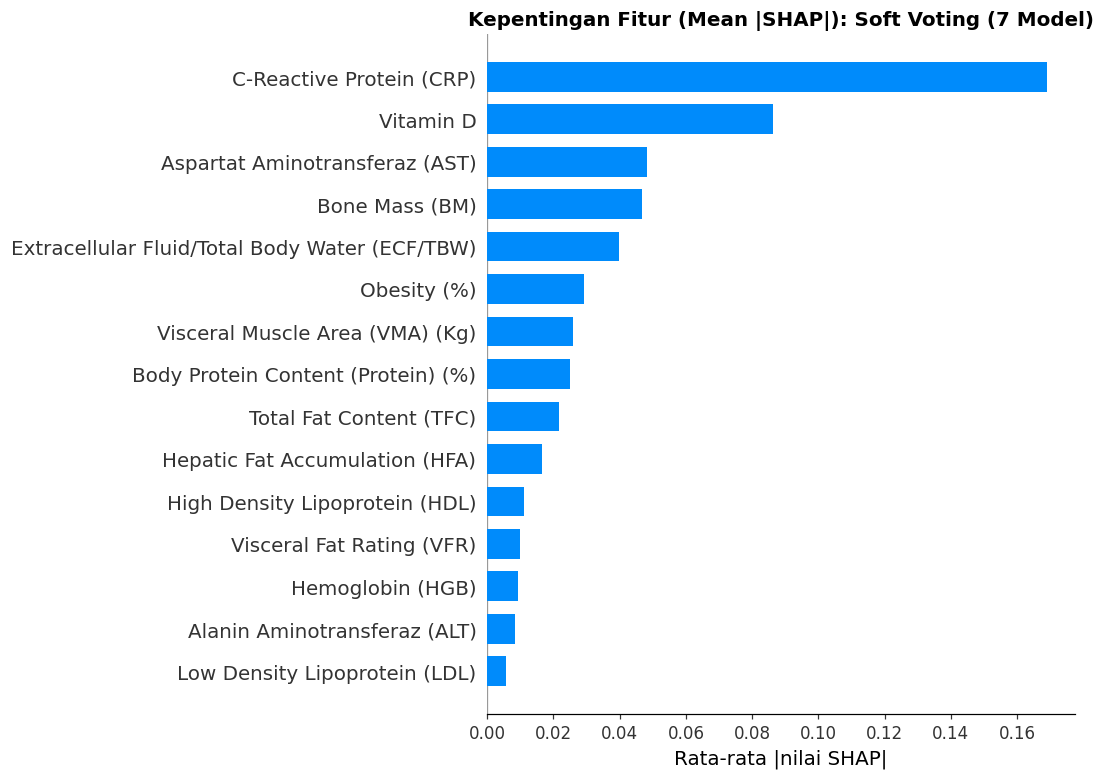

In [ ]:
# SHAP summary plot (beeswarm)
shap.summary_plot(shap_vals, X_test_model, max_display=15, show=False, plot_size=(10, 7))
plt.title(f'SHAP Summary Plot: {xai_name}', fontsize=13, fontweight='bold')
plt.xlabel('Nilai SHAP (kontribusi terhadap probabilitas kelas 1)')
save_fig('xai_01_shap_summary_beeswarm')

# SHAP bar plot (rata-rata |SHAP|)
shap.summary_plot(shap_vals, X_test_model, plot_type='bar', max_display=15, show=False, plot_size=(10, 7))
plt.title(f'Kepentingan Fitur (Mean |SHAP|): {xai_name}', fontsize=13, fontweight='bold')
plt.xlabel('Rata-rata |nilai SHAP|')
save_fig('xai_02_shap_bar')